# Healthy spectra — reproducibility, problematic frequencies, and representative dataset

**Rebuilt from the attached `healthy_frequency_cross_experiment_eda_results.ipynb`.** All primary analyses use the categorical `Reynolds_level`, exclude level 0, and preserve `file_name` as the experimental-run identifier. No requirement for identical elapsed seconds when comparing run-level distributions.

**Objectives:** (1) coverage and validation; (2) within-run temporal noise vs between-run baseline shifts; (3) identify problematic probe × Reynolds × frequency combinations with effect sizes and statistical evidence; (4) construct a **unique `(Date-Time, Reynolds_level, probe)` wide-format** representative dataset (equivalent to unique `(Date-Time, Reynolds_level, probe, frequency)` long-format). Keep the original full healthy data for time-series model training and holdout testing.

**Important:** a run may be stable but systematically different. No automatic deletion of frequencies based on a p-value. An independent experiment is a source `file_name`, not a timestamp.

In [16]:
from pathlib import Path
import re, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data').is_dir()), None)
if ROOT is None: raise FileNotFoundError('Cannot locate project root containing data/')
INPUT = ROOT/'data'/'healthy_pre_leak.csv'
OUT = ROOT/'results'/'healthy_reproducibility_v2'
OUT.mkdir(parents=True, exist_ok=True)

LEVELS = [12.5, 25., 50., 100., 150.]
STRICT_LEVEL_MATCH = False     # True: exact; False: assign nearest specified level
LEVEL_TOLERANCE = 0.1        # used only when STRICT_LEVEL_MATCH=False
MIN_RUNS = 2
TOP_N = 12
MIN_SAMPLES_PER_RUN = 10
PROBES = ['UUS','US','DS','DDS']
# Pragmatic screening thresholds; tune with engineering knowledge, not universal physical cutoffs
BETWEEN_TO_WITHIN_RATIO_THRESHOLD = 2.0
BETWEEN_SD_THRESHOLD = None   # optional absolute threshold, e.g. 5.0
ALPHA = 0.05
print('Input:',INPUT,'\nOutput:',OUT)

Input: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/data/healthy_pre_leak.csv 
Output: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/healthy_reproducibility_v2


## 1. Load, normalize, filter Reynolds levels, and audit coverage

Use `Reynolds_level` exclusively for operating-condition grouping. A tolerance match is mapped to the nearest requested level. Check duplicate keys and contamination before analysis.

In [17]:
df = pd.read_csv(INPUT, low_memory=False)
df.columns = [re.split(r'[ǀ|]',str(c))[-1].strip() for c in df.columns]
if df.columns.duplicated().any():
    raise ValueError('Duplicate columns after sensor-prefix normalization: '+str(df.columns[df.columns.duplicated()].tolist()))
required = ['file_name','probe','Date-Time','Reynolds_level']
if any(c not in df for c in required): raise ValueError(f'Missing columns: {[c for c in required if c not in df]}')
freqs = sorted([c for c in df if re.fullmatch(r'f\d+(?:\.\d+)?',c)],key=lambda c:float(c[1:]))
if not freqs: raise ValueError('No f... frequency columns found')
for c in ['Date-Time','Reynolds_level']+freqs: df[c]=pd.to_numeric(df[c],errors='coerce')
df['probe']=df['probe'].astype(str).str.strip().str.upper()
df['file_name']=df['file_name'].astype(str).str.strip().str.removesuffix('.csv')
df=df.dropna(subset=required).copy()
if 'Leak Event' in df:
    leaks=pd.to_numeric(df['Leak Event'],errors='coerce')
    if (leaks != 0).any():
        raise ValueError(f'Found {(leaks != 0).sum()} nonzero/missing leak flags in healthy input; audit extraction first')
# Remove Reynolds=0 and keep only requested discrete operating levels.
df=df.loc[df['Reynolds_level']!=0].copy()
levels=np.asarray(LEVELS,dtype=float)
if STRICT_LEVEL_MATCH:
    df=df.loc[df['Reynolds_level'].isin(levels)].copy()
else:
    distances=np.abs(df['Reynolds_level'].to_numpy()[:,None]-levels[None,:])
    nearest=distances.argmin(axis=1)
    ok=distances[np.arange(len(df)),nearest]<=LEVEL_TOLERANCE
    df=df.iloc[np.flatnonzero(ok)].copy()
    df['Reynolds_level']=levels[nearest[ok]]
if df.empty: raise ValueError('No rows remain after Reynolds filtering')
dup=df.duplicated(['file_name','probe','Date-Time'],keep=False)
print('Rows:',len(df),'frequencies:',len(freqs),'duplicate run/probe/second rows:',int(dup.sum()))
if dup.any():
    display(df.loc[dup,['file_name','probe','Date-Time','Reynolds_level']].head(15))
    raise ValueError('Resolve duplicate file/probe/time rows before proceeding')
coverage=(df.groupby(['probe','Reynolds_level'],observed=True)
          .agg(n_rows=('file_name','size'),n_runs=('file_name','nunique'),n_seconds=('Date-Time','nunique'))
          .reset_index())
coverage.to_csv(OUT/'coverage.csv',index=False)
display(coverage.pivot(index='Reynolds_level',columns='probe',values='n_runs').reindex(index=LEVELS,columns=PROBES))
print('Source files per probe and level:')
display(df.groupby(['probe','Reynolds_level'])['file_name'].unique().reset_index())

Rows: 57600 frequencies: 26 duplicate run/probe/second rows: 0


probe,UUS,US,DS,DDS
Reynolds_level,,,,
12.5,4,4,4,4
25.0,5,5,5,5
50.0,5,5,5,5
100.0,5,5,5,5
150.0,5,5,5,5


Source files per probe and level:


,probe,Reynolds_level,file_name
0,DDS,12.5,"[DDS1211_1, DDS1212_1, DDS1213_1, DDS1213_2]"
1,DDS,25.0,"[DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, D..."
2,DDS,50.0,"[DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, D..."
3,DDS,100.0,"[DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, D..."
4,DDS,150.0,"[DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, D..."
5,DS,12.5,"[DS1211_1, DS1212_1, DS1213_1, DS1213_2]"
6,DS,25.0,"[DS1211_1, DS1212_1, DS1212_2, DS1213_1, DS121..."
7,DS,50.0,"[DS1211_1, DS1212_1, DS1212_2, DS1213_1, DS121..."
8,DS,100.0,"[DS1211_1, DS1212_1, DS1212_2, DS1213_1, DS121..."
9,DS,150.0,"[DS1211_1, DS1212_1, DS1212_2, DS1213_1, DS121..."


## 2. Run-level statistics: temporal noise within each experimental run

Each file contributes **one mean** for each probe × Reynolds level × frequency. The within-run SD is computed across time samples. Temporal autocorrelation means the 600 seconds are *not* 600 independent experiments.

In [18]:
long=df.melt(id_vars=['file_name','probe','Date-Time','Reynolds_level'],value_vars=freqs,
             var_name='frequency',value_name='amplitude').dropna(subset=['amplitude'])
keys=['probe','Reynolds_level','frequency']
run_keys=keys+['file_name']
run_stats=(long.groupby(run_keys,observed=True)['amplitude']
           .agg(n_samples='size',run_mean='mean',within_run_std='std',run_median='median',
                q05=lambda x:x.quantile(.05),q95=lambda x:x.quantile(.95))
           .reset_index())
run_stats.to_csv(OUT/'within_run_statistics.csv',index=False)
display(run_stats.head(12))

,probe,Reynolds_level,frequency,file_name,n_samples,run_mean,within_run_std,run_median,q05,q95
0,DDS,12.5,f100,DDS1211_1,600,28.230387,1.654465,28.232806,25.692087,30.949308
1,DDS,12.5,f100,DDS1212_1,600,28.102801,1.551644,28.093334,25.494133,30.661860
2,DDS,12.5,f100,DDS1213_1,600,29.284880,1.576663,29.330956,26.599240,31.656448
3,DDS,12.5,f100,DDS1213_2,600,28.048171,1.662267,27.932390,25.394093,30.923863
4,DDS,12.5,f1000,DDS1211_1,600,18.671397,1.017173,18.506845,17.295571,20.385735
5,DDS,12.5,f1000,DDS1212_1,600,18.870939,0.833396,18.827290,17.530855,20.211925
6,DDS,12.5,f1000,DDS1213_1,600,18.046388,0.735860,17.995558,17.033855,19.178657
7,DDS,12.5,f1000,DDS1213_2,600,18.302557,0.931670,18.274400,17.083079,19.538843
8,DDS,12.5,f10000,DDS1211_1,600,5.142444,0.530190,4.860761,4.748534,5.952206
9,DDS,12.5,f10000,DDS1212_1,600,5.057625,0.455793,4.860761,4.748534,5.794263


## 3. Between-run consistency and frequency screening

Compute SD **across run means**, not across pooled seconds. Also report typical within-run SD and the ratio `between_run_sd / median_within_run_sd`. A large ratio indicates run-specific baseline shifts; a large within-run SD indicates temporal fluctuations. `n_runs=1` means between-run SD is **unknown**, not zero.

In [19]:
eligible=run_stats[run_stats['n_samples']>=MIN_SAMPLES_PER_RUN].copy()
between=(eligible.groupby(keys,observed=True)
         .agg(n_runs=('file_name','nunique'),mean_amplitude=('run_mean','mean'),
              between_run_std=('run_mean','std'),run_mean_min=('run_mean','min'),
              run_mean_max=('run_mean','max'),median_within_run_std=('within_run_std','median'),
              max_within_run_std=('within_run_std','max'))
         .reset_index())
between['run_mean_range']=between['run_mean_max']-between['run_mean_min']
between['between_to_within_ratio']=between['between_run_std']/between['median_within_run_std'].where(between['median_within_run_std']>1e-8)
between['between_cv']=between['between_run_std']/between['mean_amplitude'].abs().where(between['mean_amplitude'].abs()>1e-8)
between['has_replication']=between['n_runs']>=MIN_RUNS
between['problematic_candidate']=(between['has_replication'] &
    (between['between_to_within_ratio']>=BETWEEN_TO_WITHIN_RATIO_THRESHOLD))
if BETWEEN_SD_THRESHOLD is not None:
    between['problematic_candidate'] |= between['has_replication'] & (between['between_run_std']>=BETWEEN_SD_THRESHOLD)
between=between.sort_values(['Reynolds_level','probe','between_run_std'],ascending=[True,True,False])
between.to_csv(OUT/'between_run_frequency_screening.csv',index=False)
print('Replicated groups:',int(between.has_replication.sum()),'of',len(between))
print('Flagged candidates:',int(between.problematic_candidate.sum()))
display(between.groupby(['probe','Reynolds_level'],group_keys=False).head(TOP_N))

Replicated groups: 520 of 520
Flagged candidates: 147


,probe,Reynolds_level,frequency,n_runs,mean_amplitude,between_run_std,run_mean_min,run_mean_max,median_within_run_std,max_within_run_std,run_mean_range,between_to_within_ratio,between_cv,has_replication,problematic_candidate
7,DDS,12.5,f200,4,40.138050,4.513333,35.253928,45.099516,1.942811,2.269270,9.845588,2.323095,0.112445,True,True
10,DDS,12.5,f250,4,41.810399,1.868117,40.763498,44.604965,0.694314,1.539408,3.841467,2.690592,0.044681,True,True
15,DDS,12.5,f400,4,30.001275,1.827758,28.765914,32.719904,1.265017,1.666474,3.953990,1.444849,0.060923,True,False
5,DDS,12.5,f160,4,31.404871,1.728326,29.020788,32.959253,1.457693,1.532645,3.938464,1.185659,0.055034,True,False
13,DDS,12.5,f315,4,29.008925,1.029911,28.304399,30.535427,0.818183,1.085239,2.231028,1.258778,0.035503,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
519,UUS,150.0,f8000,5,4.903161,1.495273,3.436891,7.119857,2.594116,4.504946,3.682965,0.576410,0.304961,True,False
509,UUS,150.0,f400,5,33.791945,1.399453,32.825133,36.125487,1.044167,1.207180,3.300354,1.340257,0.041414,True,False
499,UUS,150.0,f160,5,32.510262,1.134474,31.074146,34.018053,1.433586,1.739917,2.943907,0.791354,0.034896,True,False
516,UUS,150.0,f6300,5,3.377532,0.878911,2.670295,4.768842,1.793359,3.247792,2.098547,0.490092,0.260223,True,False


## 4. Heatmaps: between-run SD and within-run SD, separately by Reynolds level

Missing between-run SD is shown as gray (no replicated runs). Every probe is displayed, even when no replicated runs exist.

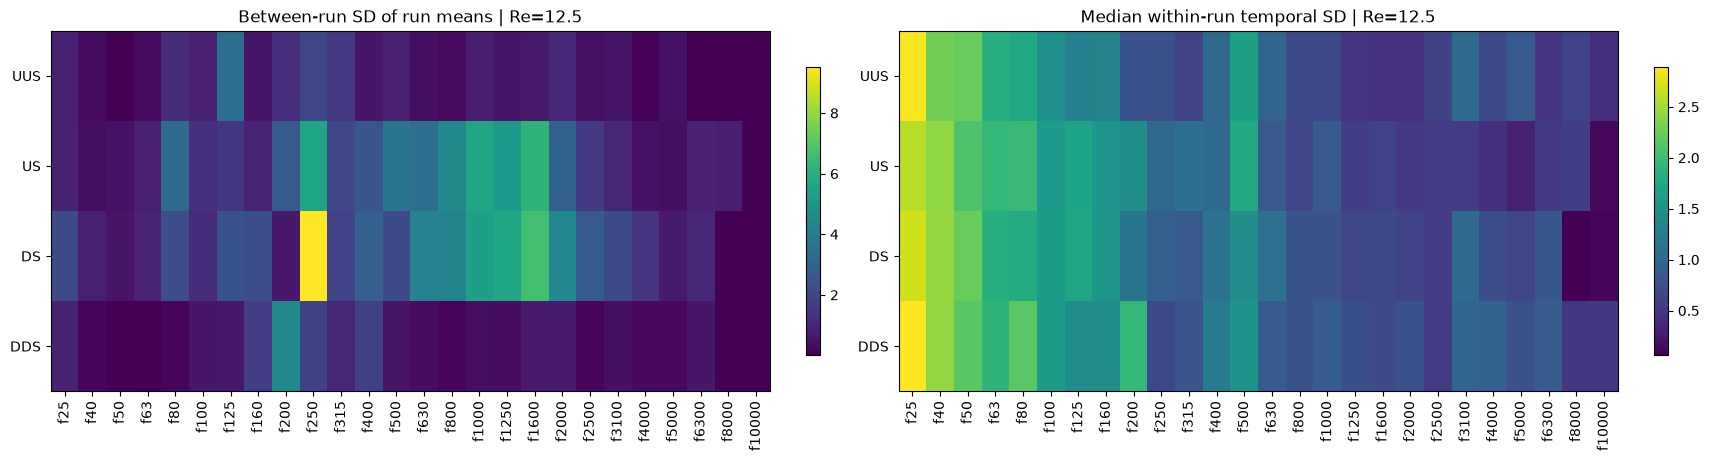

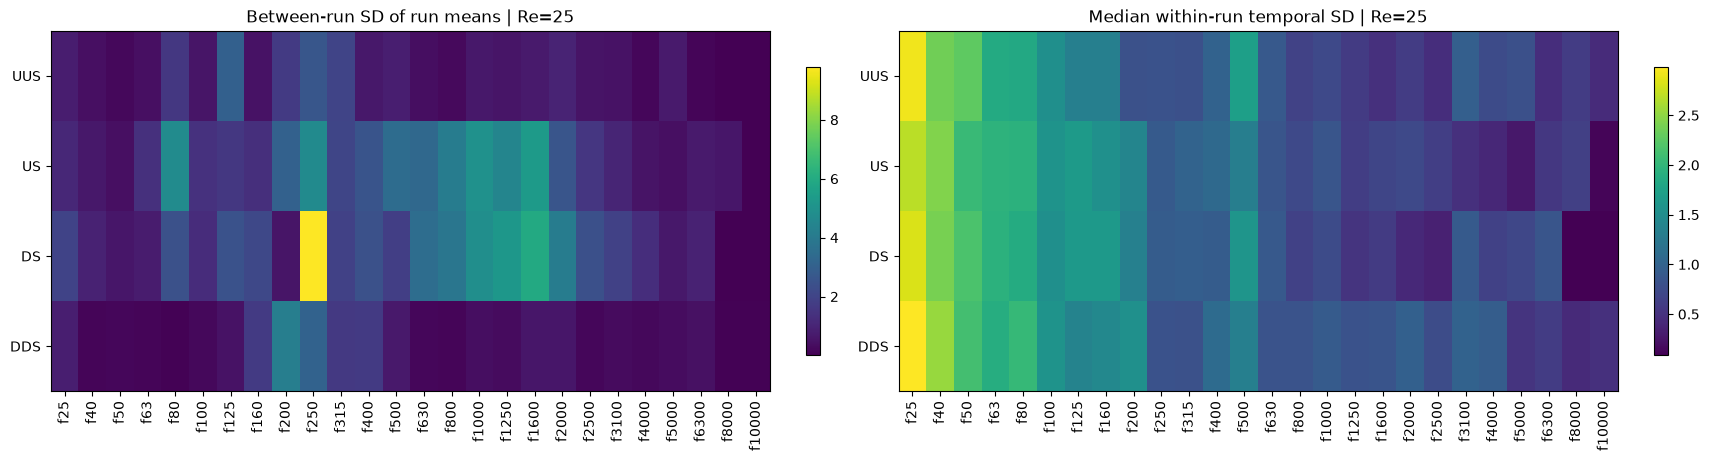

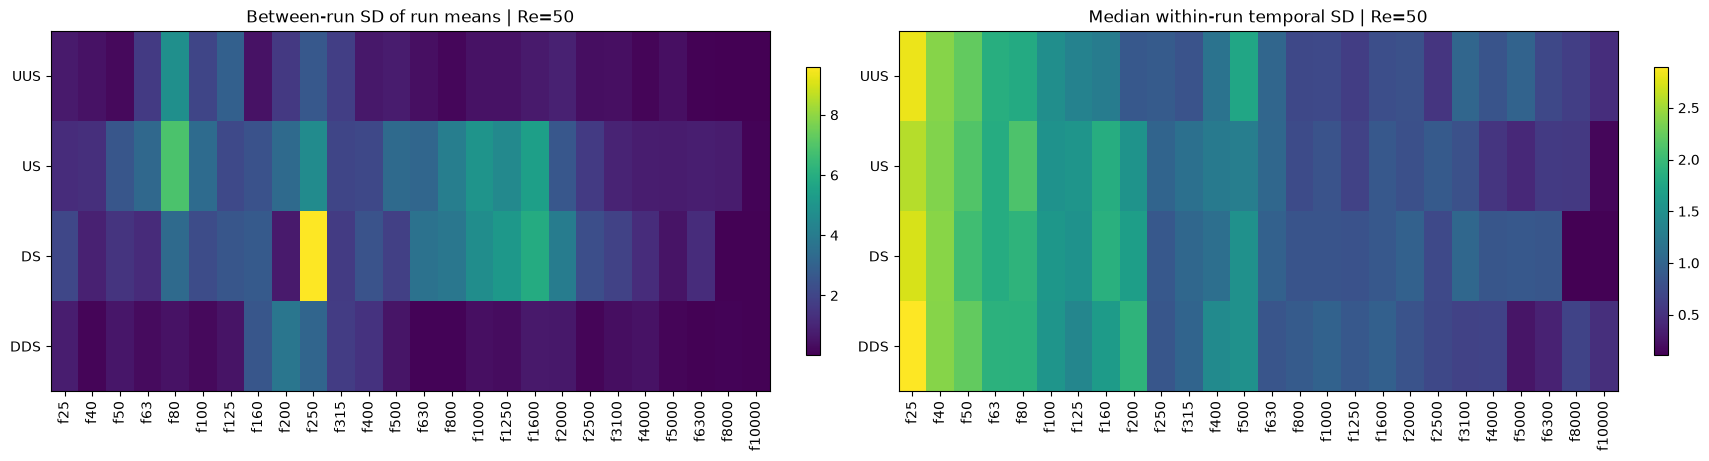

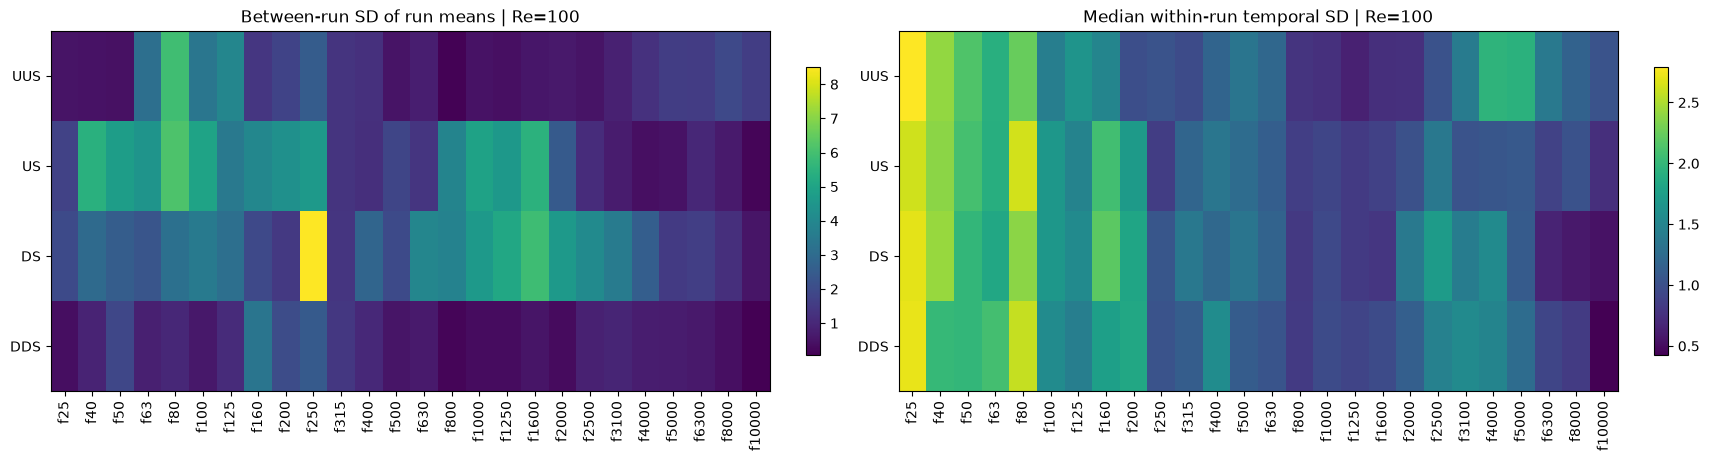

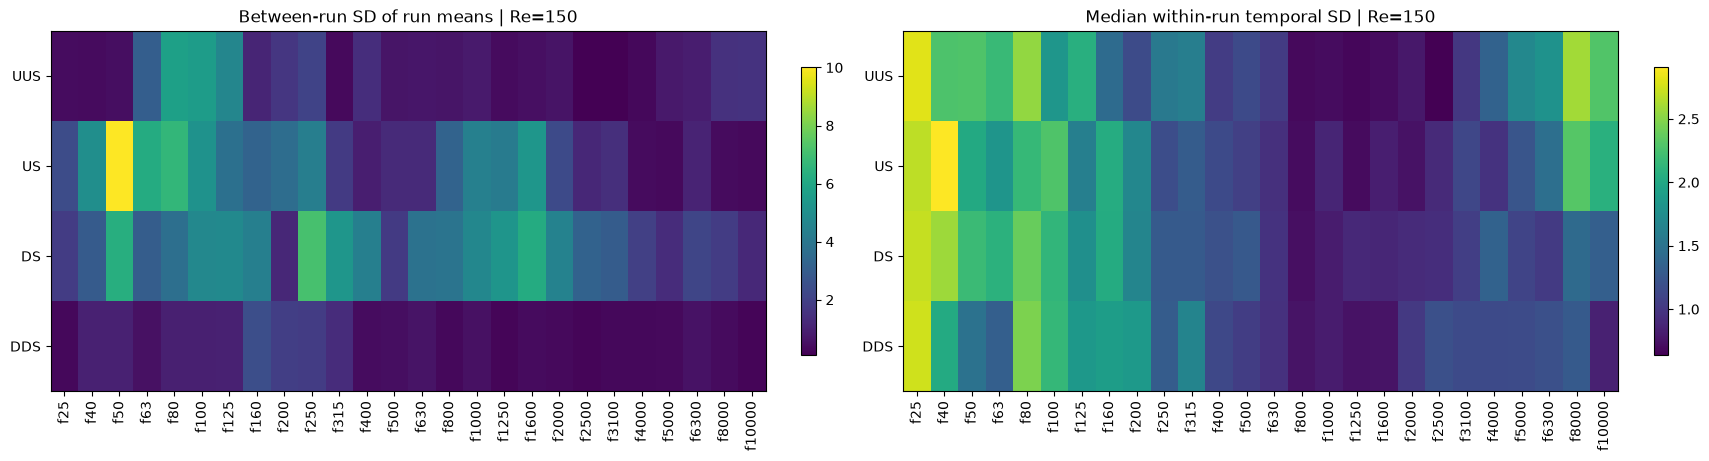

In [20]:
for level in LEVELS:
    subset=between[between['Reynolds_level']==level]
    fig,axes=plt.subplots(1,2,figsize=(17,4.5),layout='constrained')
    for ax,metric,title in zip(axes,['between_run_std','median_within_run_std'],
                               ['Between-run SD of run means','Median within-run temporal SD']):
        p=subset.pivot(index='probe',columns='frequency',values=metric).reindex(index=PROBES,columns=freqs)
        a=np.ma.masked_invalid(p.to_numpy(dtype=float))
        cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#dddddd')
        im=ax.imshow(a,aspect='auto',cmap=cmap)
        ax.set_yticks(range(len(PROBES)),PROBES)
        ax.set_xticks(range(len(freqs)),freqs,rotation=90)
        ax.set_title(f'{title} | Re={level:g}')
        fig.colorbar(im,ax=ax,shrink=.8)
    fig.savefig(OUT/f'run_variability_Re_{level:g}.png',dpi=160)
    plt.show()

In [21]:
import pandas as pd

raw = pd.read_csv("../data/healthy_pre_leak.csv")

# 1. List every source file and its number of rows
print("=== ALL SOURCE FILES ===")
display(
    raw.groupby(["probe", "file_name"])
       .size()
       .reset_index(name="n_rows")
       .sort_values(["probe", "file_name"])
)

# 2. Check experiment coverage at EVERY Reynolds level
print("=== EXPERIMENTS PER PROBE AND REYNOLDS LEVEL ===")

coverage = (
    raw.groupby(["probe", "Reynolds_level"])
       .agg(
           n_rows=("file_name", "size"),
           n_runs=("file_name", "nunique"),
           files=("file_name", lambda x: ", ".join(sorted(x.unique())))
       )
       .reset_index()
       .sort_values(["Reynolds_level", "probe"])
)

display(coverage)

# 3. Show coverage as a matrix
print("=== NUMBER OF RUNS PER PROBE × REYNOLDS ===")

display(
    coverage.pivot(
        index="Reynolds_level",
        columns="probe",
        values="n_runs"
    ).reindex(columns=["UUS", "US", "DS", "DDS"])
)

# 4. Verify whether US/DDS have multiple runs in the raw data
print("=== US AND DDS SOURCE FILES ===")

display(
    coverage[coverage["probe"].isin(["US", "DDS"])]
)

=== ALL SOURCE FILES ===


,probe,file_name,n_rows
0,DDS,DDS1211_1,3000
1,DDS,DDS1212_1,3000
2,DDS,DDS1212_2,3000
3,DDS,DDS1213_1,3300
4,DDS,DDS1213_2,3000
5,DS,DS1211_1,3000
6,DS,DS1212_1,3000
7,DS,DS1212_2,3000
8,DS,DS1213_1,3300
9,DS,DS1213_2,3000


=== EXPERIMENTS PER PROBE AND REYNOLDS LEVEL ===


,probe,Reynolds_level,n_rows,n_runs,files
0,DDS,0.0,900,2,"DDS1212_2, DDS1213_1"
6,DS,0.0,900,2,"DS1212_2, DS1213_1"
12,US,0.0,900,2,"US1212_2, US1213_1"
18,UUS,0.0,900,2,"UUS1212_2, UUS1213_1"
1,DDS,12.5,2400,4,"DDS1211_1, DDS1212_1, DDS1213_1, DDS1213_2"
7,DS,12.5,2400,4,"DS1211_1, DS1212_1, DS1213_1, DS1213_2"
13,US,12.5,2400,4,"US1211_1, US1212_1, US1213_1, US1213_2"
19,UUS,12.5,2400,4,"UUS1211_1, UUS1212_1, UUS1213_1, UUS1213_2"
2,DDS,25.0,3000,5,"DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, DD..."
8,DS,25.0,3000,5,"DS1211_1, DS1212_1, DS1212_2, DS1213_1, DS1213_2"


=== NUMBER OF RUNS PER PROBE × REYNOLDS ===


probe,UUS,US,DS,DDS
Reynolds_level,,,,
0.0,2,2,2,2
12.5,4,4,4,4
25.0,5,5,5,5
50.0,5,5,5,5
100.0,5,5,5,5
150.0,5,5,5,5


=== US AND DDS SOURCE FILES ===


,probe,Reynolds_level,n_rows,n_runs,files
0,DDS,0.0,900,2,"DDS1212_2, DDS1213_1"
12,US,0.0,900,2,"US1212_2, US1213_1"
1,DDS,12.5,2400,4,"DDS1211_1, DDS1212_1, DDS1213_1, DDS1213_2"
13,US,12.5,2400,4,"US1211_1, US1212_1, US1213_1, US1213_2"
2,DDS,25.0,3000,5,"DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, DD..."
14,US,25.0,3000,5,"US1211_1, US1212_1, US1212_2, US1213_1, US1213_2"
3,DDS,50.0,3000,5,"DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, DD..."
15,US,50.0,3000,5,"US1211_1, US1212_1, US1212_2, US1213_1, US1213_2"
4,DDS,100.0,3000,5,"DDS1211_1, DDS1212_1, DDS1212_2, DDS1213_1, DD..."
16,US,100.0,3000,5,"US1211_1, US1212_1, US1212_2, US1213_1, US1213_2"


## 5. Statistical evidence of run differences (diagnostic, not automatic rejection)

For each probe × Reynolds × frequency with at least two runs and sufficient samples, test equality of run distributions using **Kruskal–Wallis** (nonparametric, exploratory) and report effect-size proxies (run-mean range and between/within SD). Apply **Benjamini–Hochberg FDR** across tested combinations. **Caution:** Kruskal–Wallis treats timestamps as independent; acoustic series are autocorrelated, so its p-values can be anti-conservative. They are **screening indicators only**, not confirmatory significance. Confirm with run-aware block bootstrap or additional independent runs before concluding a frequency is defective. With only one run, no cross-run test is possible.

In [22]:
import pandas as pd

raw = pd.read_csv("../data/healthy_pre_leak.csv")

raw["run_id"] = raw["file_name"].str.extract(
    r"(1211_1|1212_1|1212_2|1213_1|1213_2)$"
)

# Reynolds distribution by experiment and probe
check = (
    raw.groupby(["run_id", "probe"])
    .agg(
        n_rows=("Reynolds_level", "size"),
        re_min=("Reynolds", "min"),
        re_max=("Reynolds", "max"),
        re_unique=("Reynolds", "nunique")
    )
    .reset_index()
)

display(check.sort_values(["run_id", "probe"]))

display(
    raw.groupby(["run_id", "probe"])["Reynolds_level"]
       .apply(lambda x: sorted(x.dropna().unique()))
       .unstack("probe")
)

,run_id,probe,n_rows,re_min,re_max,re_unique
0,1211_1,DDS,3000,12.500000,150.0,2401
1,1211_1,DS,3000,12.500000,150.0,2401
2,1211_1,US,3000,12.500000,150.0,2401
3,1211_1,UUS,3000,12.500000,150.0,2401
4,1212_1,DDS,3000,12.500000,150.0,2401
5,1212_1,DS,3000,12.500000,150.0,2401
6,1212_1,US,3000,12.500000,150.0,2401
7,1212_1,UUS,3000,12.500000,150.0,2401
8,1212_2,DDS,3000,0.000000,150.0,2401
9,1212_2,DS,3000,0.000000,150.0,2401


probe,DDS,DS,US,UUS
run_id,,,,
1211_1,"[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]"
1212_1,"[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]"
1212_2,"[0.0, 25.0, 50.0, 100.0, 150.0]","[0.0, 25.0, 50.0, 100.0, 150.0]","[0.0, 25.0, 50.0, 100.0, 150.0]","[0.0, 25.0, 50.0, 100.0, 150.0]"
1213_1,"[0.0, 12.5, 25.0, 50.0, 100.0, 150.0]","[0.0, 12.5, 25.0, 50.0, 100.0, 150.0]","[0.0, 12.5, 25.0, 50.0, 100.0, 150.0]","[0.0, 12.5, 25.0, 50.0, 100.0, 150.0]"
1213_2,"[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]","[12.5, 25.0, 50.0, 100.0, 150.0]"


In [23]:
def bh_adjust(p):
    p=np.asarray(p,float);out=np.full(len(p),np.nan)
    valid=np.flatnonzero(np.isfinite(p))
    if not len(valid):return out
    order=valid[np.argsort(p[valid])];m=len(order)
    adjusted=np.minimum.accumulate((p[order]*m/np.arange(1,m+1))[::-1])[::-1]
    out[order]=np.clip(adjusted,0,1)
    return out

records=[]
for (probe,level,freq),g in long.groupby(keys,observed=True,sort=False):
    arrays=[x['amplitude'].to_numpy(dtype=float) for _,x in g.groupby('file_name') if len(x)>=MIN_SAMPLES_PER_RUN]
    if len(arrays)<2:continue
    try:
        h,p=stats.kruskal(*arrays)
    except ValueError: h,p=np.nan,np.nan  # all identical
    records.append(dict(probe=probe,Reynolds_level=level,frequency=freq,
                        n_runs=len(arrays),kw_H=h,kw_p=p))
tests=pd.DataFrame(records)
if not tests.empty:
    tests['kw_q_fdr']=bh_adjust(tests['kw_p'])
    tests['kw_screen_flag']=tests['kw_q_fdr']<ALPHA
    tests=tests.merge(between[keys+['between_run_std','median_within_run_std',
                                   'between_to_within_ratio','problematic_candidate']],on=keys,how='left')
    tests=tests.sort_values(['Reynolds_level','probe','kw_q_fdr'])
    display(tests.head(20))
tests.to_csv(OUT/'exploratory_kruskal_fdr.csv',index=False)
print('Tests:',len(tests),'(exploratory: temporal autocorrelation is not modeled)')

,probe,Reynolds_level,frequency,n_runs,kw_H,kw_p,kw_q_fdr,kw_screen_flag,between_run_std,median_within_run_std,between_to_within_ratio,problematic_candidate
160,DDS,12.5,f200,4,1928.799937,0.000000e+00,0.000000e+00,True,4.513333,1.942811,2.323095,True
340,DDS,12.5,f1600,4,1475.344255,0.000000e+00,0.000000e+00,True,0.687192,0.723948,0.949228,False
360,DDS,12.5,f2000,4,1548.295902,0.000000e+00,0.000000e+00,True,0.703197,0.775054,0.907289,False
180,DDS,12.5,f250,4,1355.754298,1.175020e-293,2.424645e-293,True,1.868117,0.694314,2.690592,True
200,DDS,12.5,f315,4,1264.257778,8.377464e-274,1.625478e-273,True,1.029911,0.818183,1.258778,False
220,DDS,12.5,f400,4,1262.802871,1.732974e-273,3.349988e-273,True,1.827758,1.265017,1.444849,False
140,DDS,12.5,f160,4,1229.407500,3.052771e-266,5.772513e-266,True,1.728326,1.457693,1.185659,False
460,DDS,12.5,f6300,4,662.797345,2.447200e-143,3.688533e-143,True,0.583534,0.878961,0.663891,False
380,DDS,12.5,f2500,4,597.834937,2.969943e-129,4.374987e-129,True,0.138500,0.551623,0.251077,False
320,DDS,12.5,f1250,4,514.636868,3.210376e-111,4.598886e-111,True,0.333054,0.748248,0.445111,False


Tests: 520 (exploratory: temporal autocorrelation is not modeled)


In [60]:
cols = [
    'probe', 'Reynolds_level', 'frequency', 'between_run_std',
    'median_within_run_std', 'between_to_within_ratio',
    'problematic_candidate'
]

def filter_ret_freq(df, levels=[100.0, 150.0], freq_min=250, freq_max=630):
    freq_numeric = pd.to_numeric(
        df["frequency"].str.removeprefix("f").str.replace("_", "."),
        errors="coerce"
    )

    sub = df[
        df["Reynolds_level"].isin(levels) &
        freq_numeric.between(freq_min, freq_max)
    ].copy()

    return sub

filtered_tests = filter_ret_freq(tests[cols])
display(filtered_tests.sort_values(['between_to_within_ratio','Reynolds_level']))#.tail())
filtered_tests

,probe,Reynolds_level,frequency,between_run_std,median_within_run_std,between_to_within_ratio,problematic_candidate
219,UUS,150.0,f315,0.333302,1.610609,0.206942,False
224,DDS,150.0,f400,0.400606,1.125905,0.355808,False
258,UUS,100.0,f500,0.507128,1.348407,0.376094,False
244,DDS,150.0,f500,0.441795,1.052690,0.419682,False
243,DDS,100.0,f500,0.554186,1.115068,0.496997,False
259,UUS,150.0,f500,0.650947,1.144672,0.568675,False
264,DDS,150.0,f630,0.609469,0.962232,0.633390,False
278,UUS,100.0,f630,0.775423,1.217225,0.637042,False
263,DDS,100.0,f630,0.672203,1.041762,0.645255,False
223,DDS,100.0,f400,1.046229,1.579311,0.662459,False


## 6. Inspect problematic frequencies: run means and temporal traces

Select one flagged frequency (or the largest between-run SD) and show run means plus raw time traces. Inspect whether differences are persistent run offsets, drift, or transient artifacts.

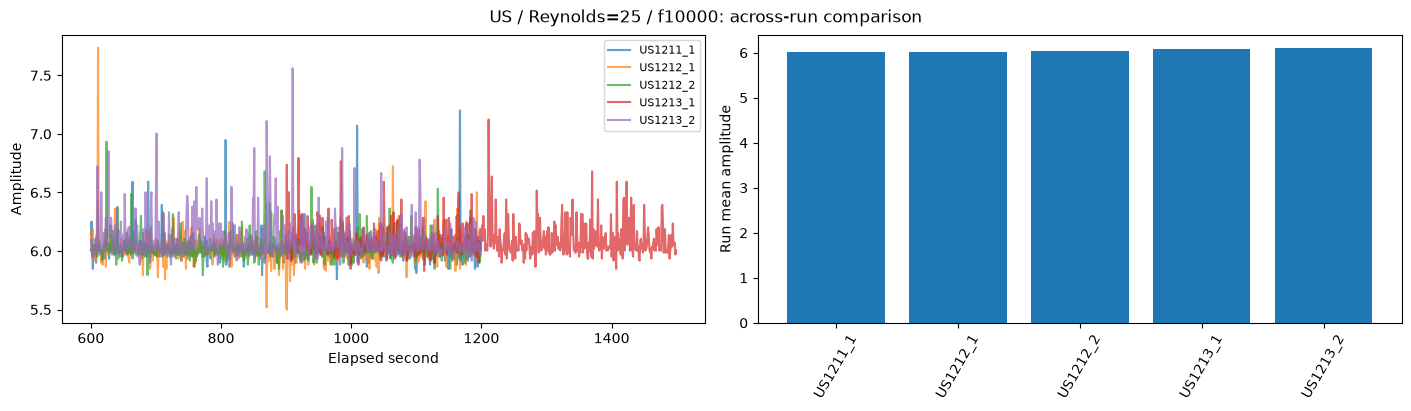

In [31]:
candidates=between.loc[between['has_replication']].sort_values('between_run_std',ascending=False)
if not candidates.empty:
    item=candidates.iloc[-1]
    probe,level,freq=item['probe'],item['Reynolds_level'],item['frequency']
    sub=long[(long['probe']==probe)&(long['Reynolds_level']==level)&(long['frequency']==freq)]
    fig,axes=plt.subplots(1,2,figsize=(14,4),layout='constrained')
    for file,g in sub.groupby('file_name'):
        axes[0].plot(g['Date-Time'],g['amplitude'],alpha=.7,label=file)
    means=sub.groupby('file_name')['amplitude'].mean().sort_values()
    axes[1].bar(means.index,means.values)
    axes[1].tick_params(axis='x',rotation=60)
    axes[0].legend(fontsize=8);axes[0].set_xlabel('Elapsed second');axes[0].set_ylabel('Amplitude')
    axes[1].set_ylabel('Run mean amplitude')
    fig.suptitle(f'{probe} / Reynolds={level:g} / {freq}: across-run comparison')
    fig.savefig(OUT/'example_problematic_frequency.png',dpi=160)
    plt.show()
else:
    print('No replicated groups to inspect')

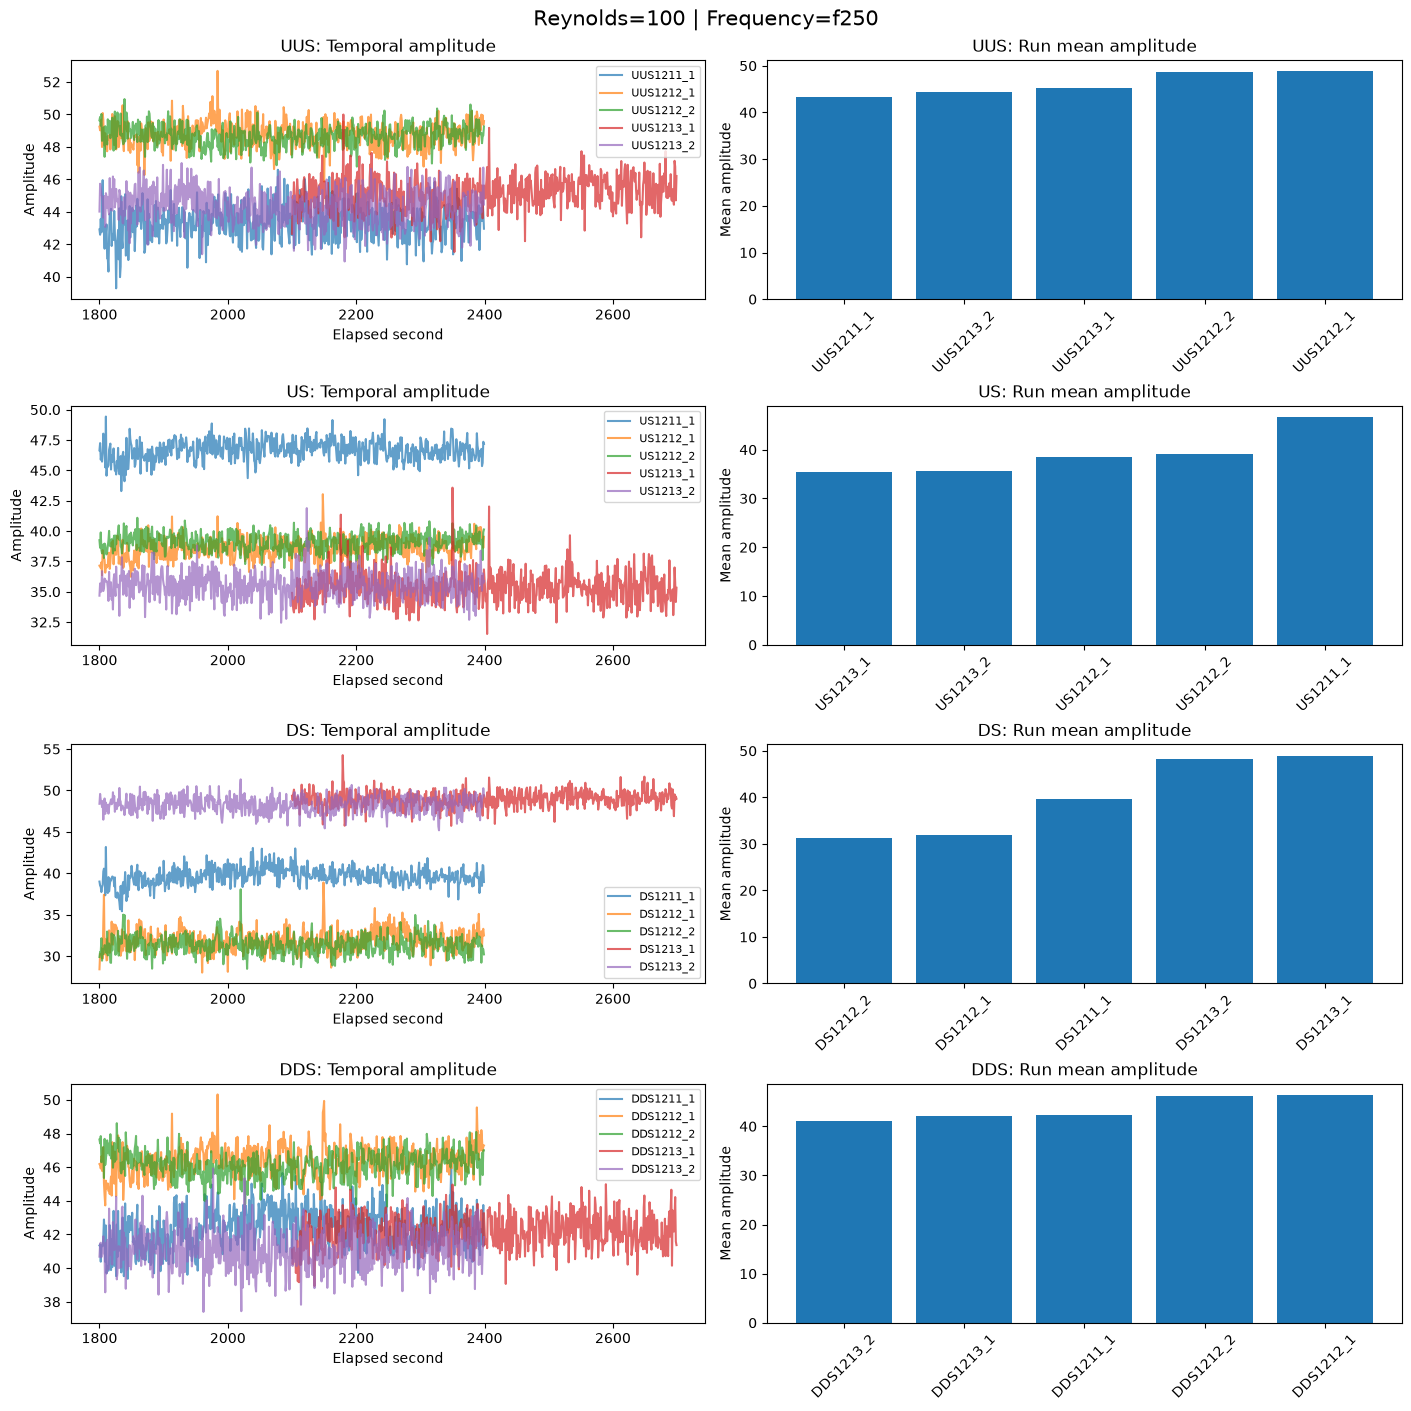

In [56]:

# User inputs
level = 100
freq = "f250"#"f315"

probes = ["UUS", "US", "DS", "DDS"]

fig, axes = plt.subplots(
    4, 2, figsize=(14, 14), layout="constrained"
)

for i, probe in enumerate(probes):
    sub = long[
        (long["probe"] == probe) &
        (long["Reynolds_level"] == level) &
        (long["frequency"] == freq)
    ].copy()

    ax_time, ax_mean = axes[i]

    if sub.empty:
        ax_time.text(0.5, 0.5, "No data",
                     ha="center", va="center",
                     transform=ax_time.transAxes)
        ax_mean.axis("off")
        continue

    # Left: temporal amplitude across experiments
    for file, g in sub.groupby("file_name"):
        g = g.sort_values("Date-Time")
        ax_time.plot(
            g["Date-Time"], g["amplitude"],
            alpha=0.7, label=file
        )

    ax_time.set_title(f"{probe}: Temporal amplitude")
    ax_time.set_xlabel("Elapsed second")
    ax_time.set_ylabel("Amplitude")
    ax_time.legend(fontsize=8)

    # Right: mean amplitude for each experiment
    means = (
        sub.groupby("file_name")["amplitude"]
        .mean()
        .sort_values()
    )

    ax_mean.bar(means.index, means.values)
    ax_mean.set_title(f"{probe}: Run mean amplitude")
    ax_mean.set_ylabel("Mean amplitude")
    ax_mean.tick_params(axis="x", rotation=45)

fig.suptitle(
    f"Reynolds={level:g} | Frequency={freq}",
    fontsize=15
)

fig.savefig(
    OUT / f"comparison_Re_{level:g}_{freq}.png",
    dpi=160
)

plt.show()


Generating 10 figures


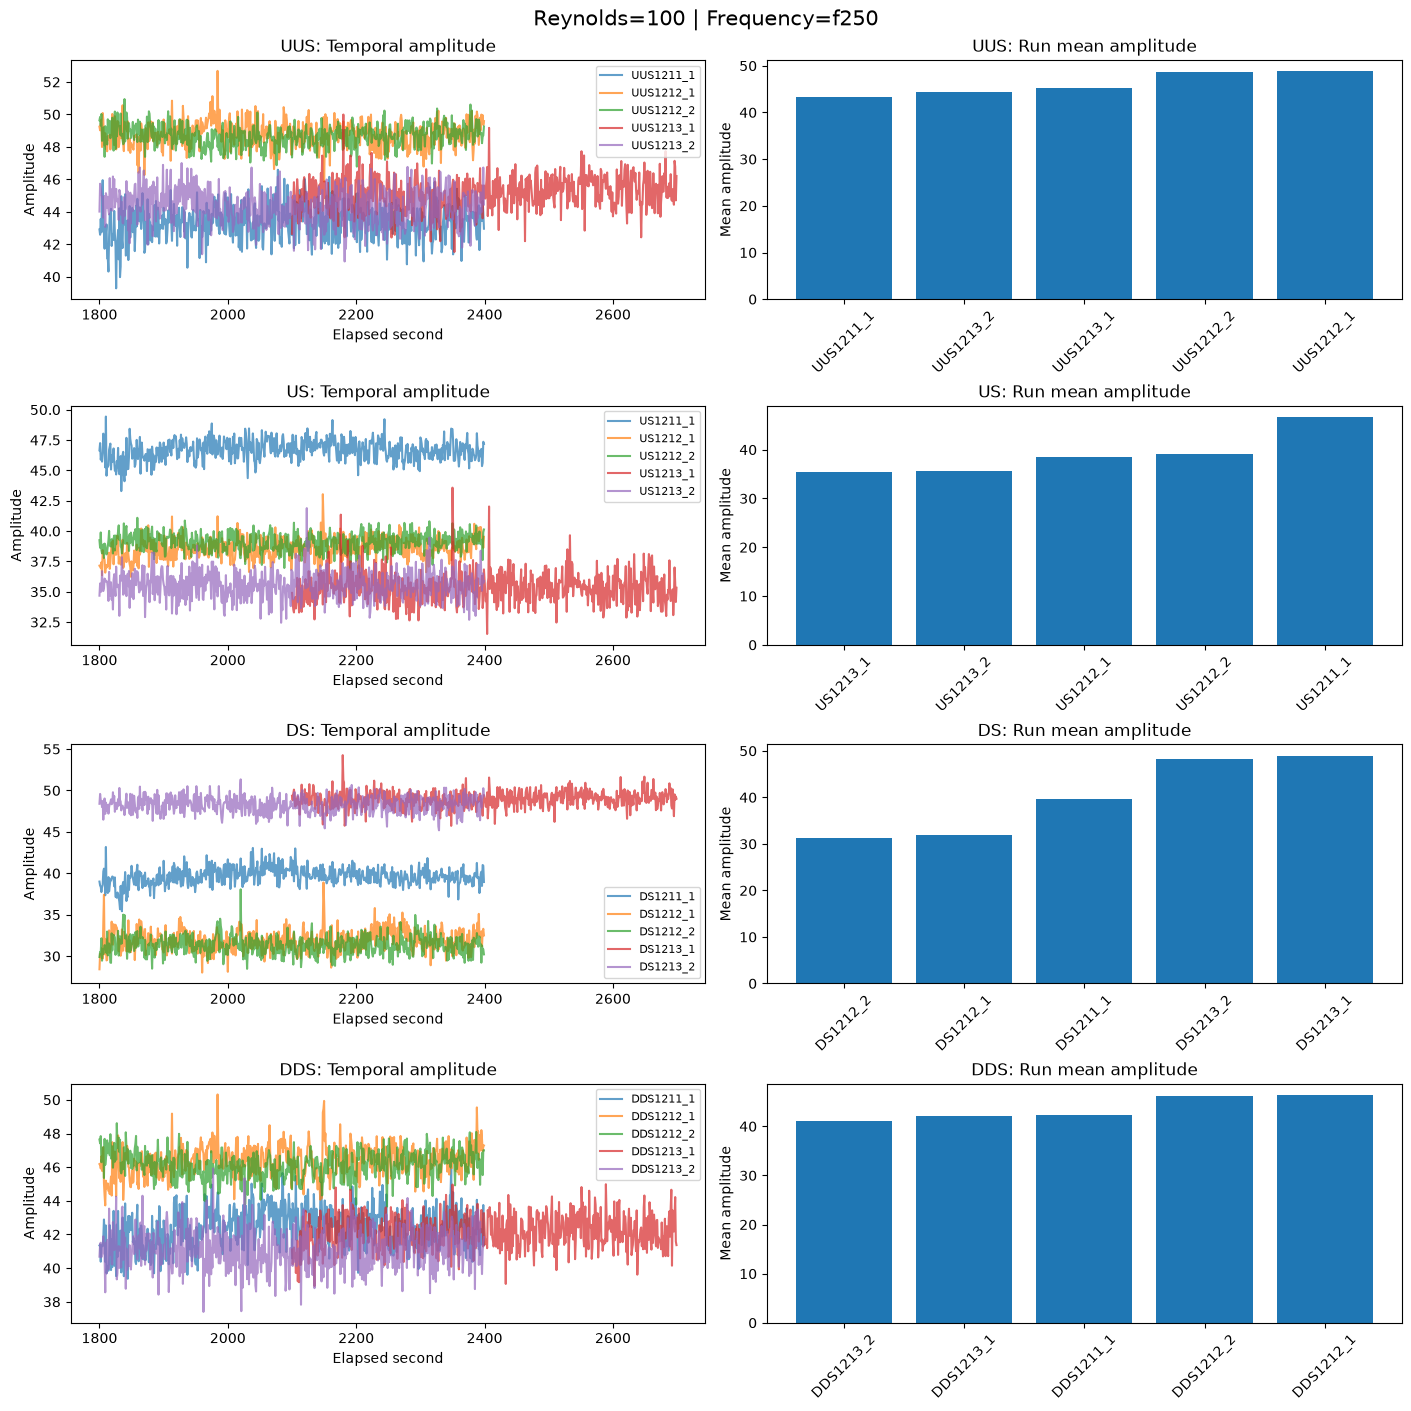

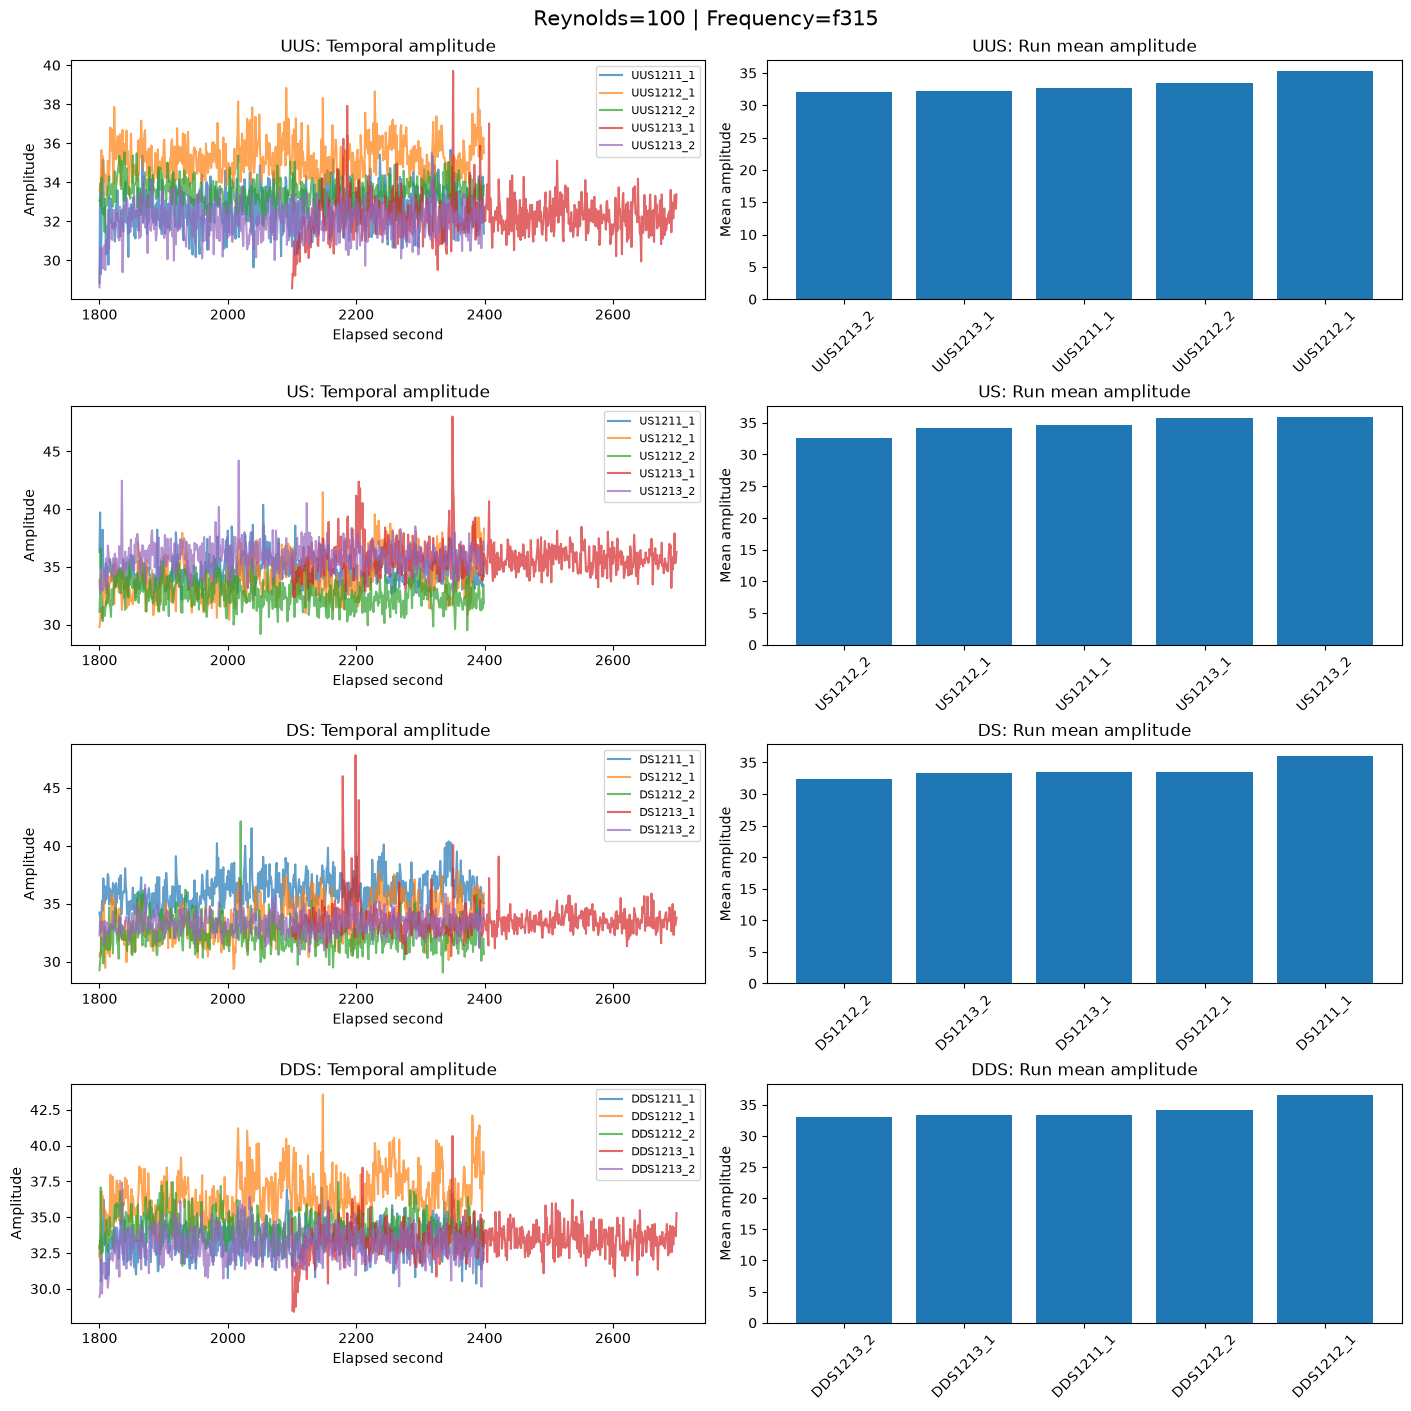

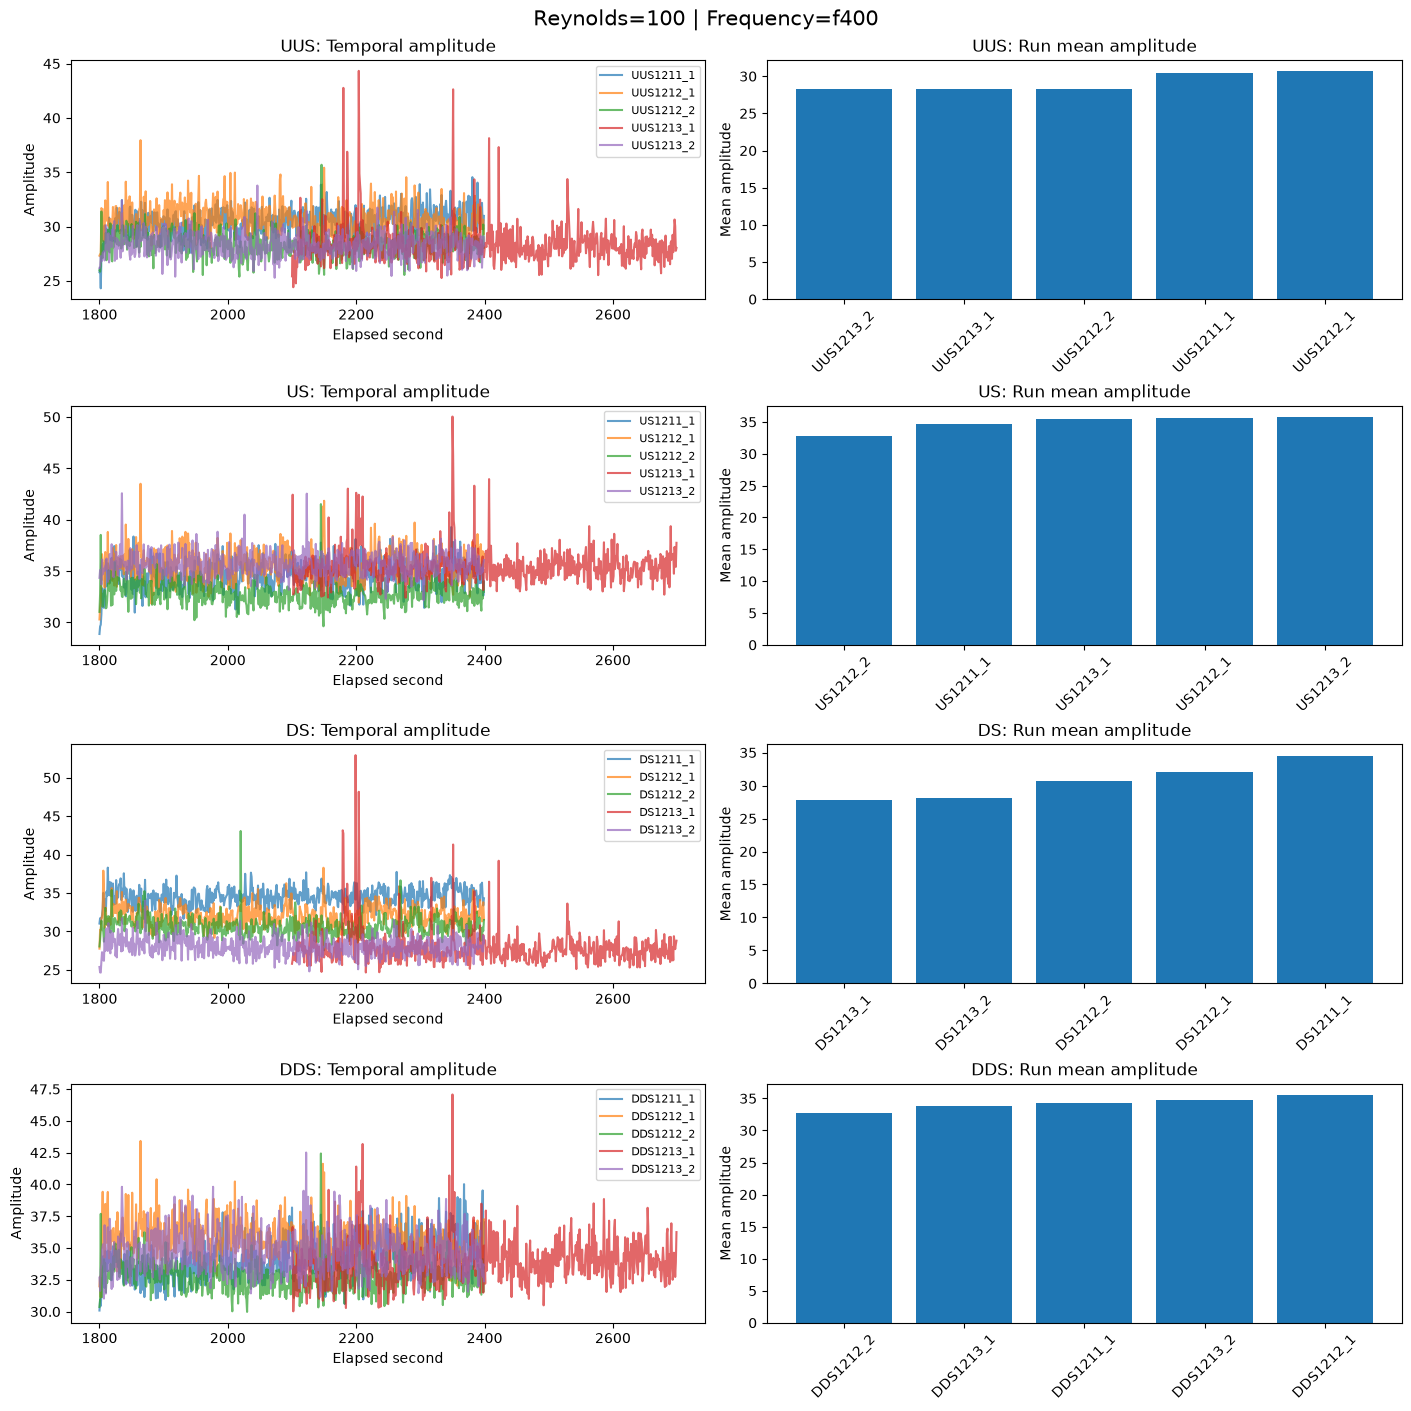

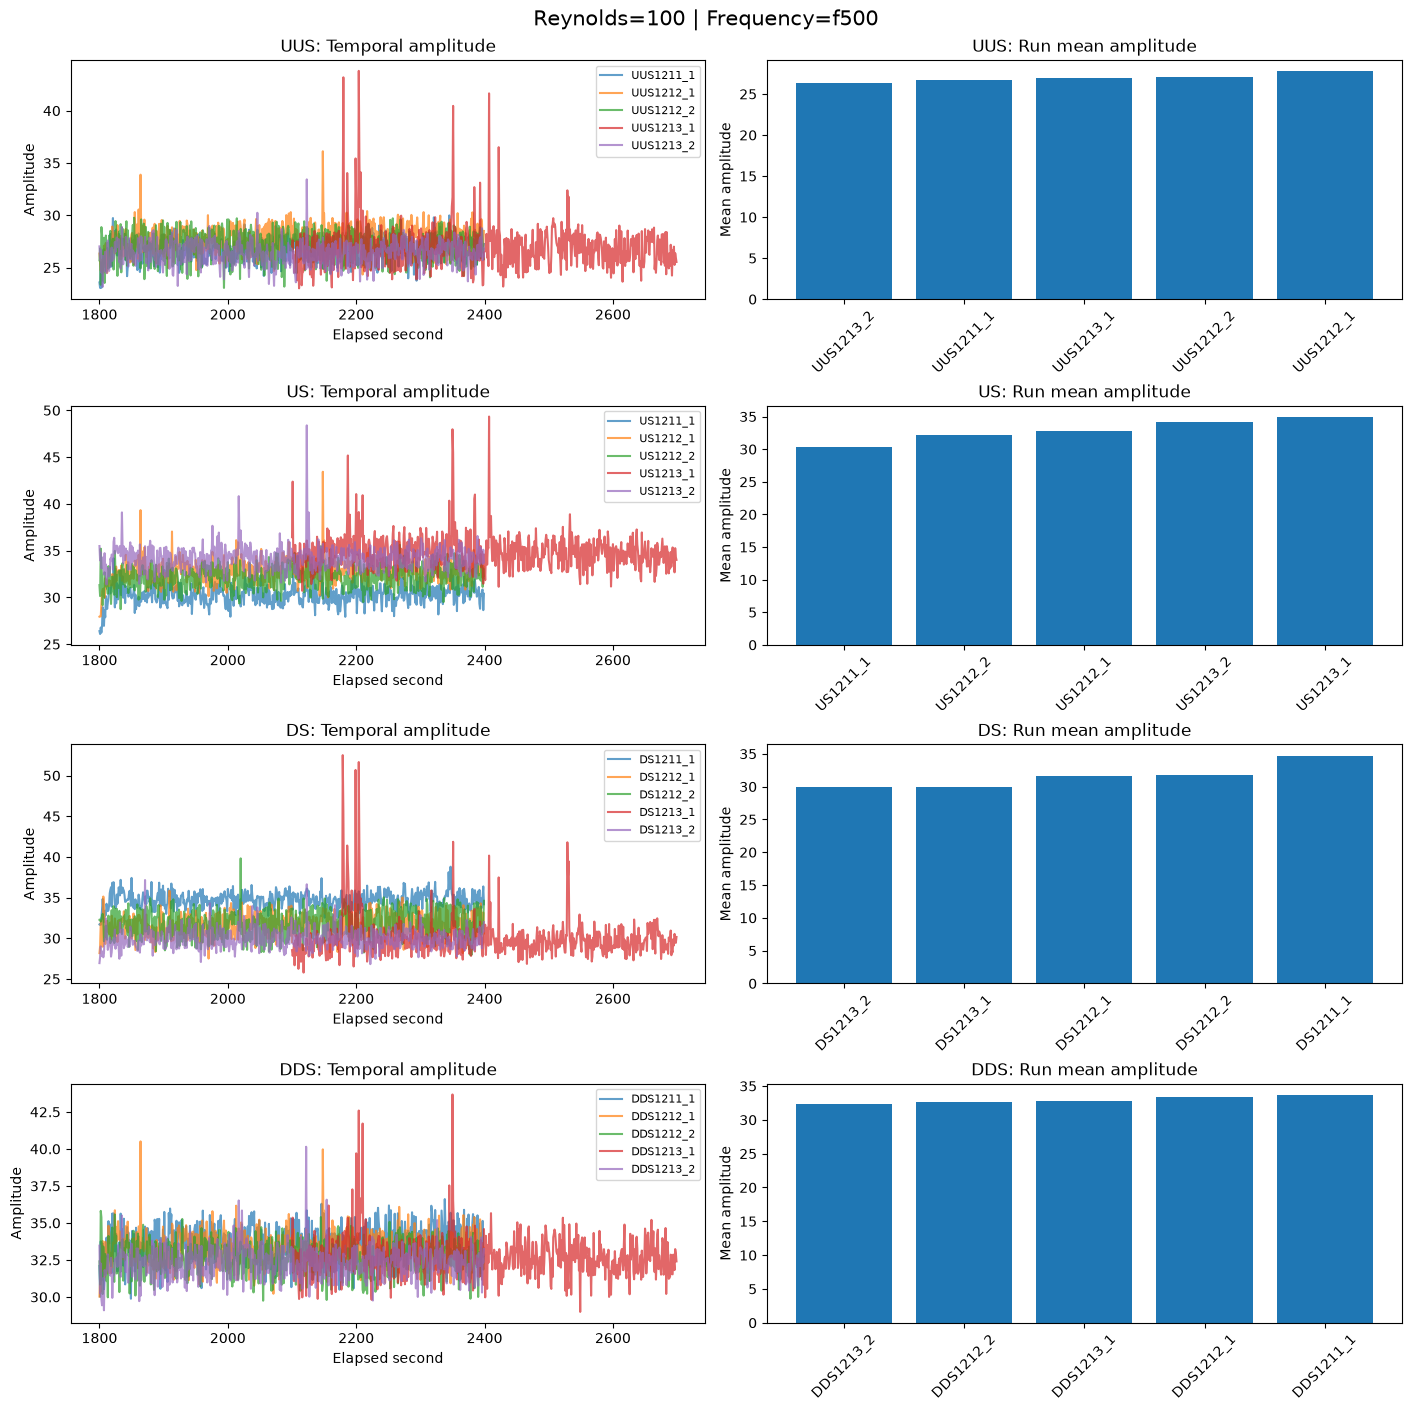

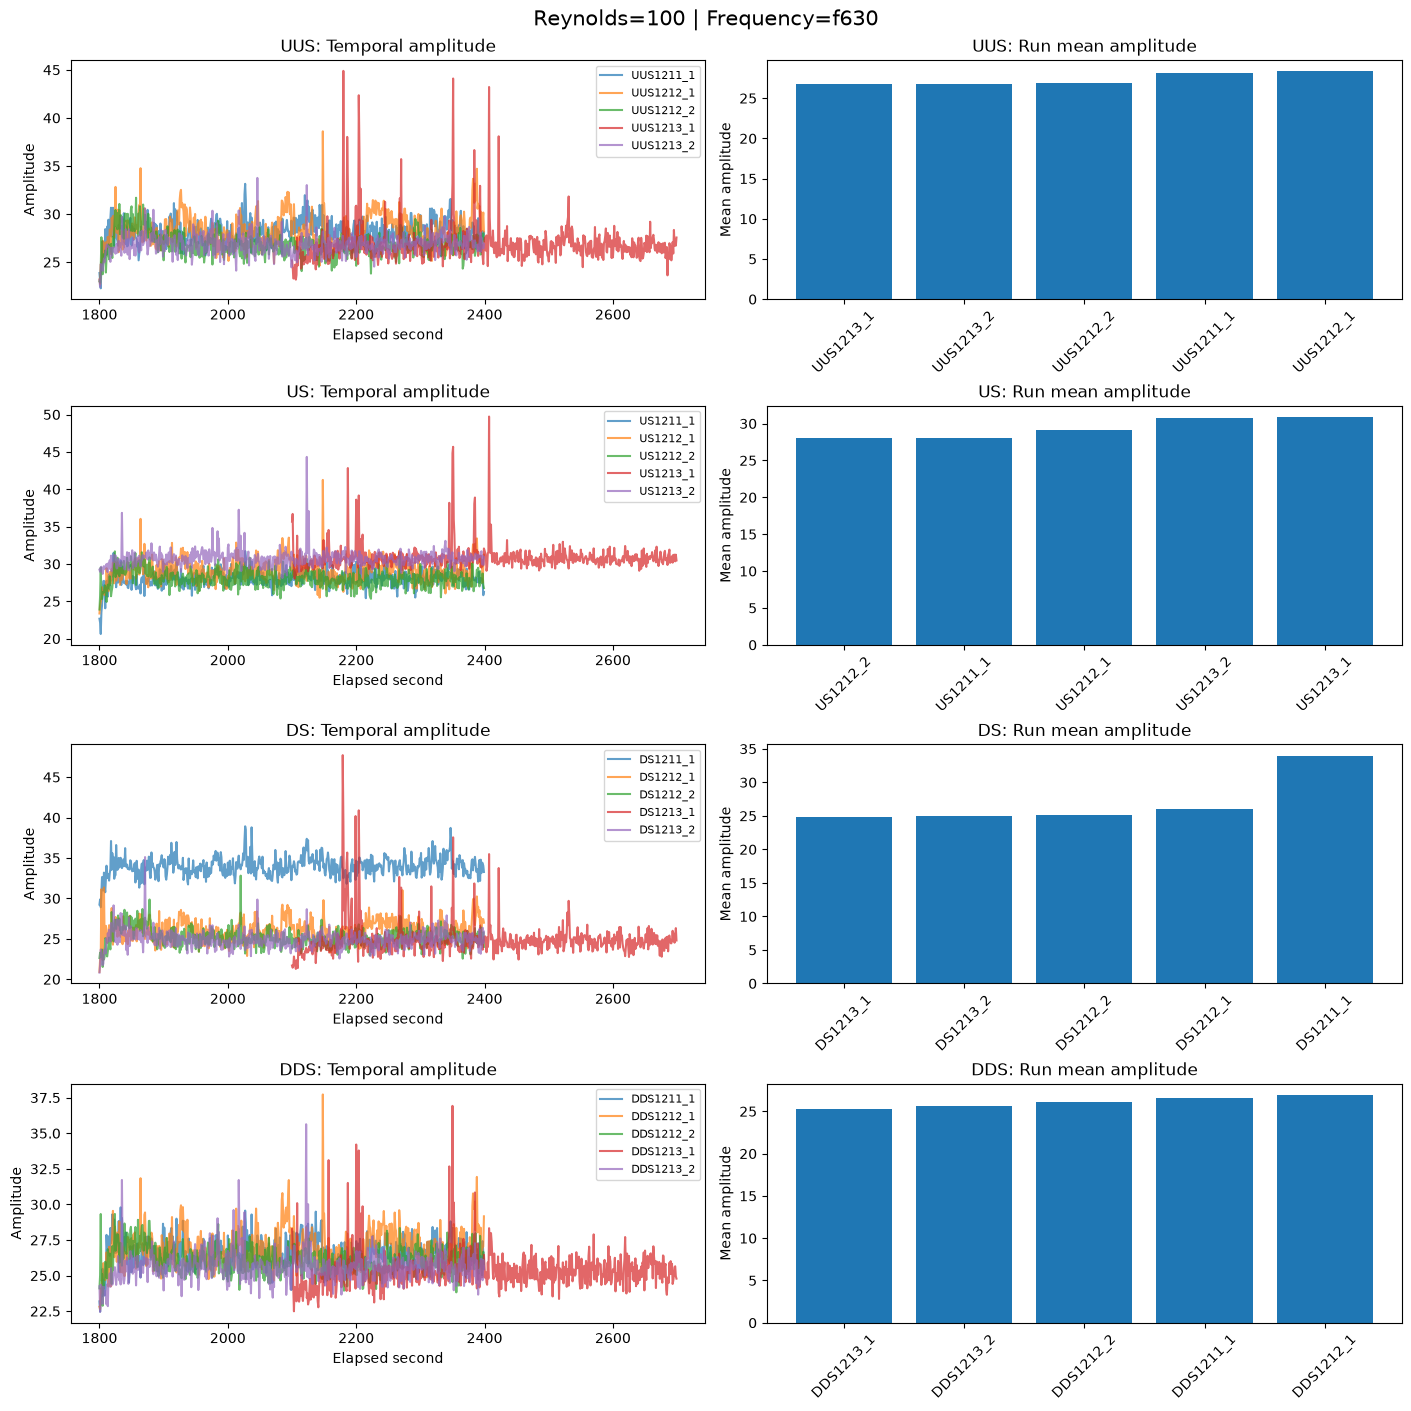

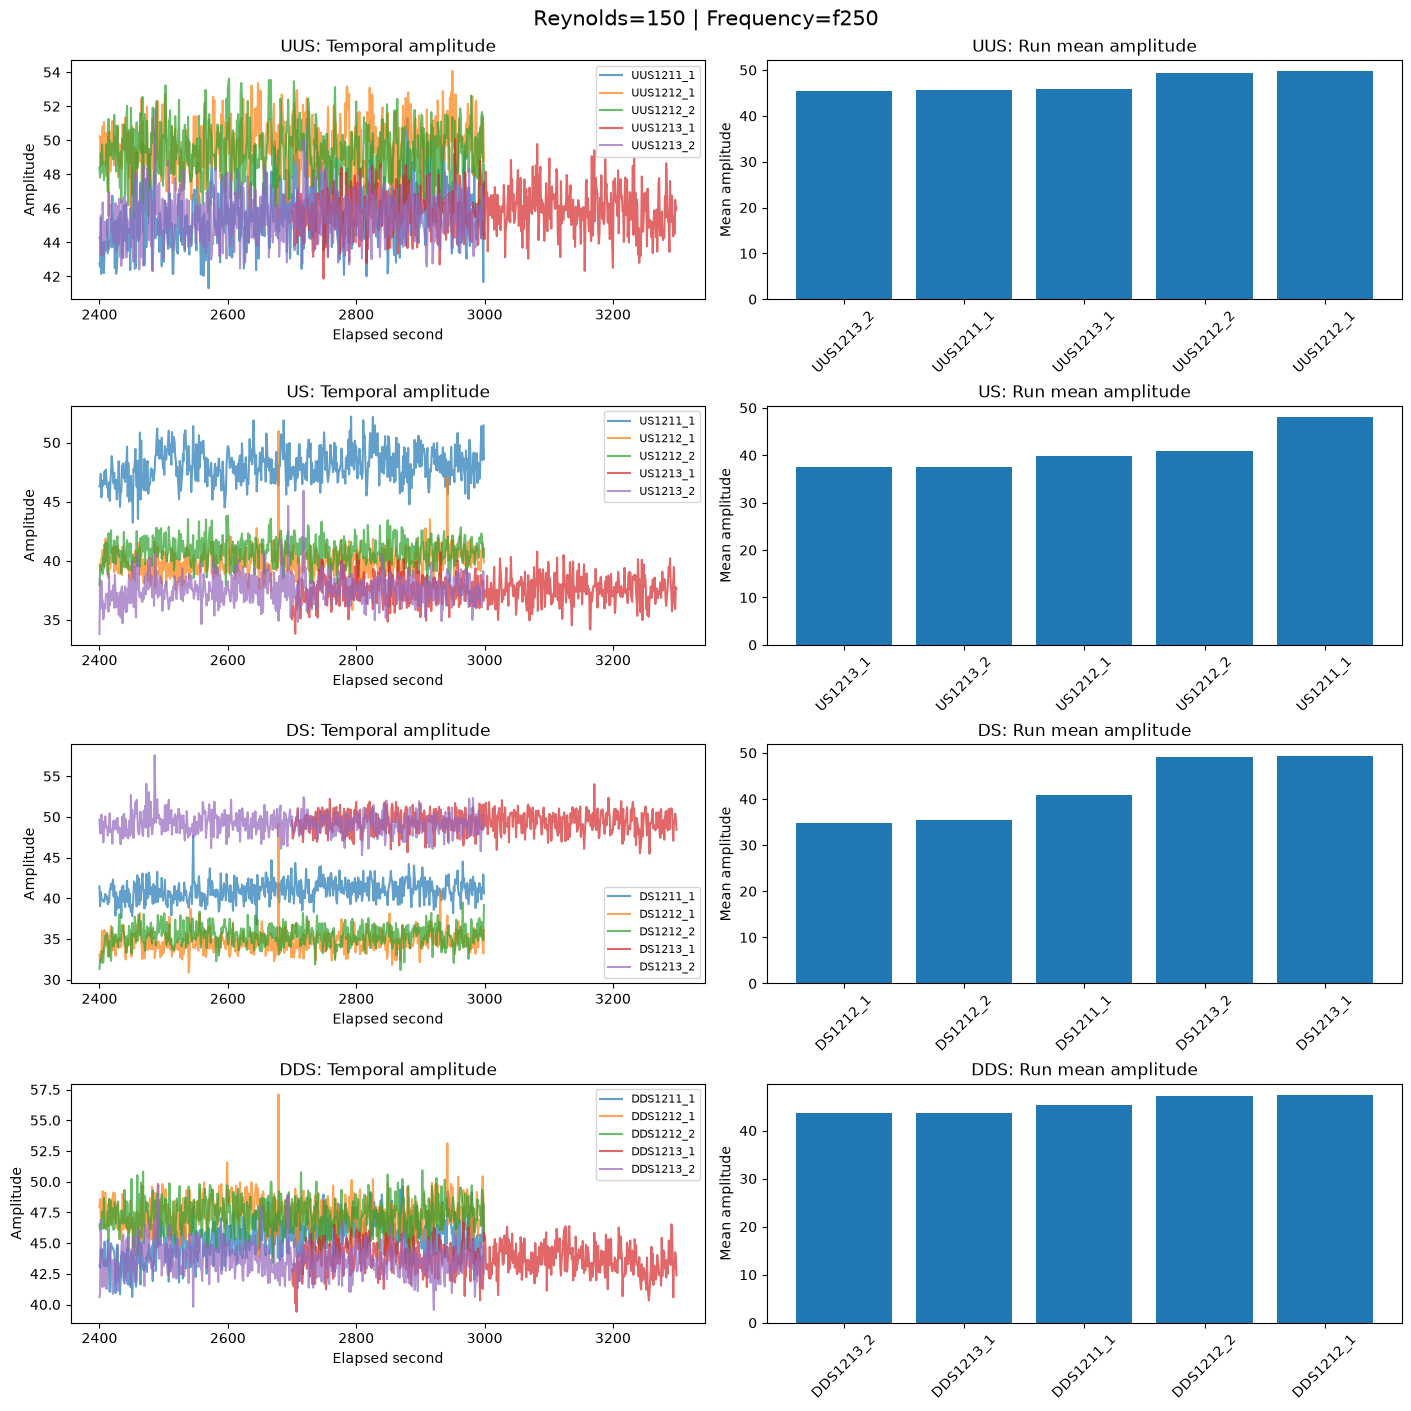

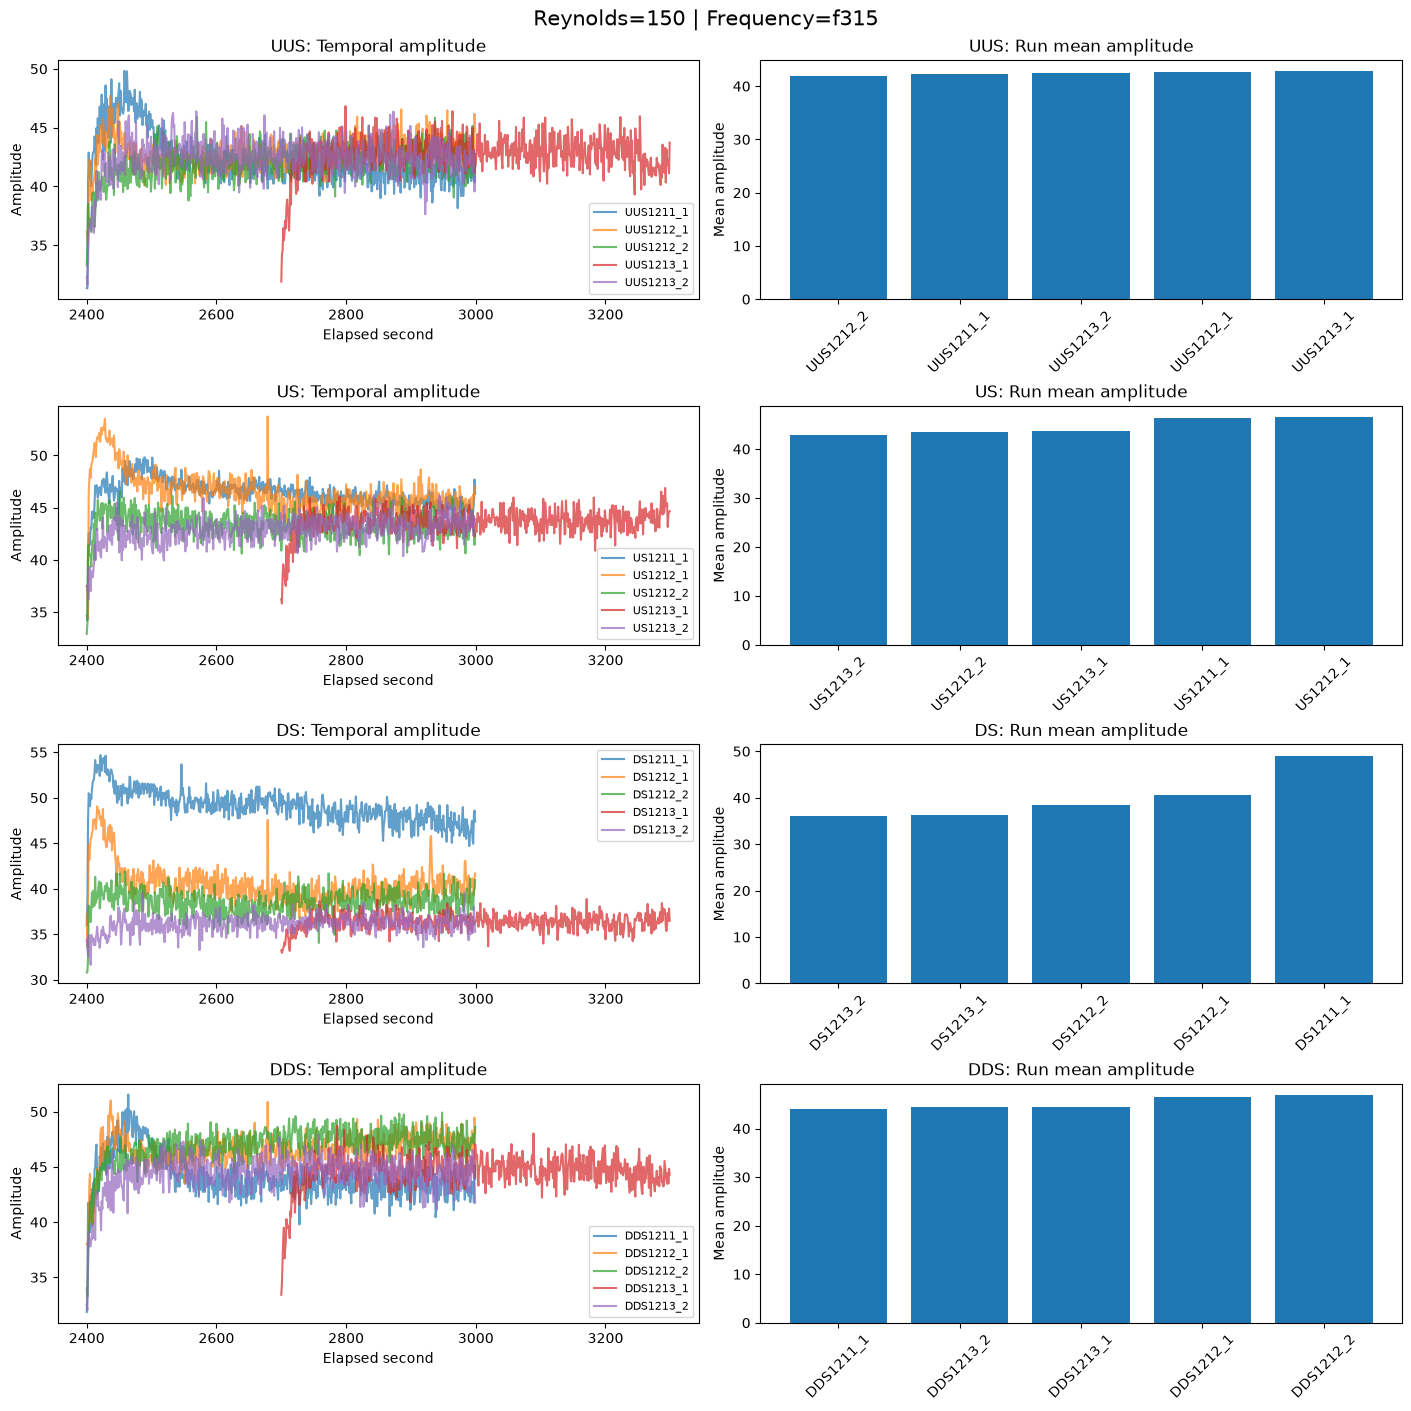

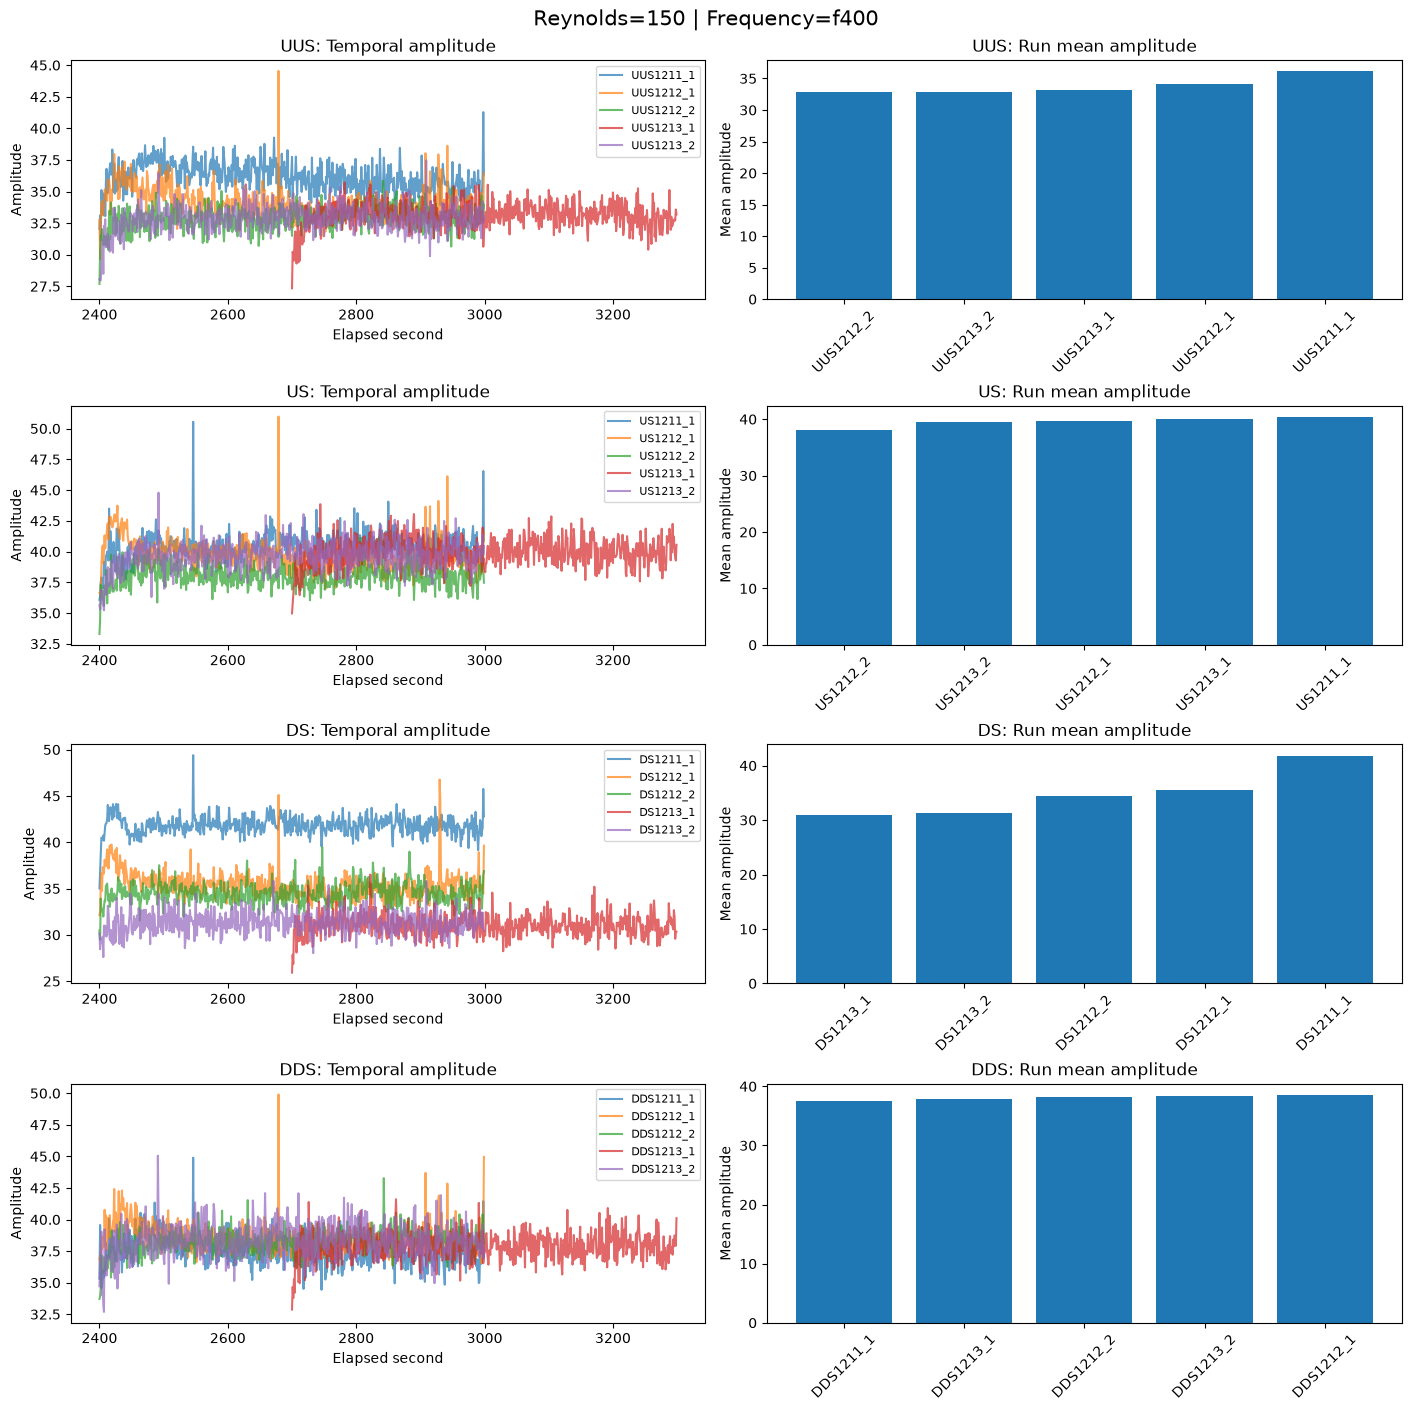

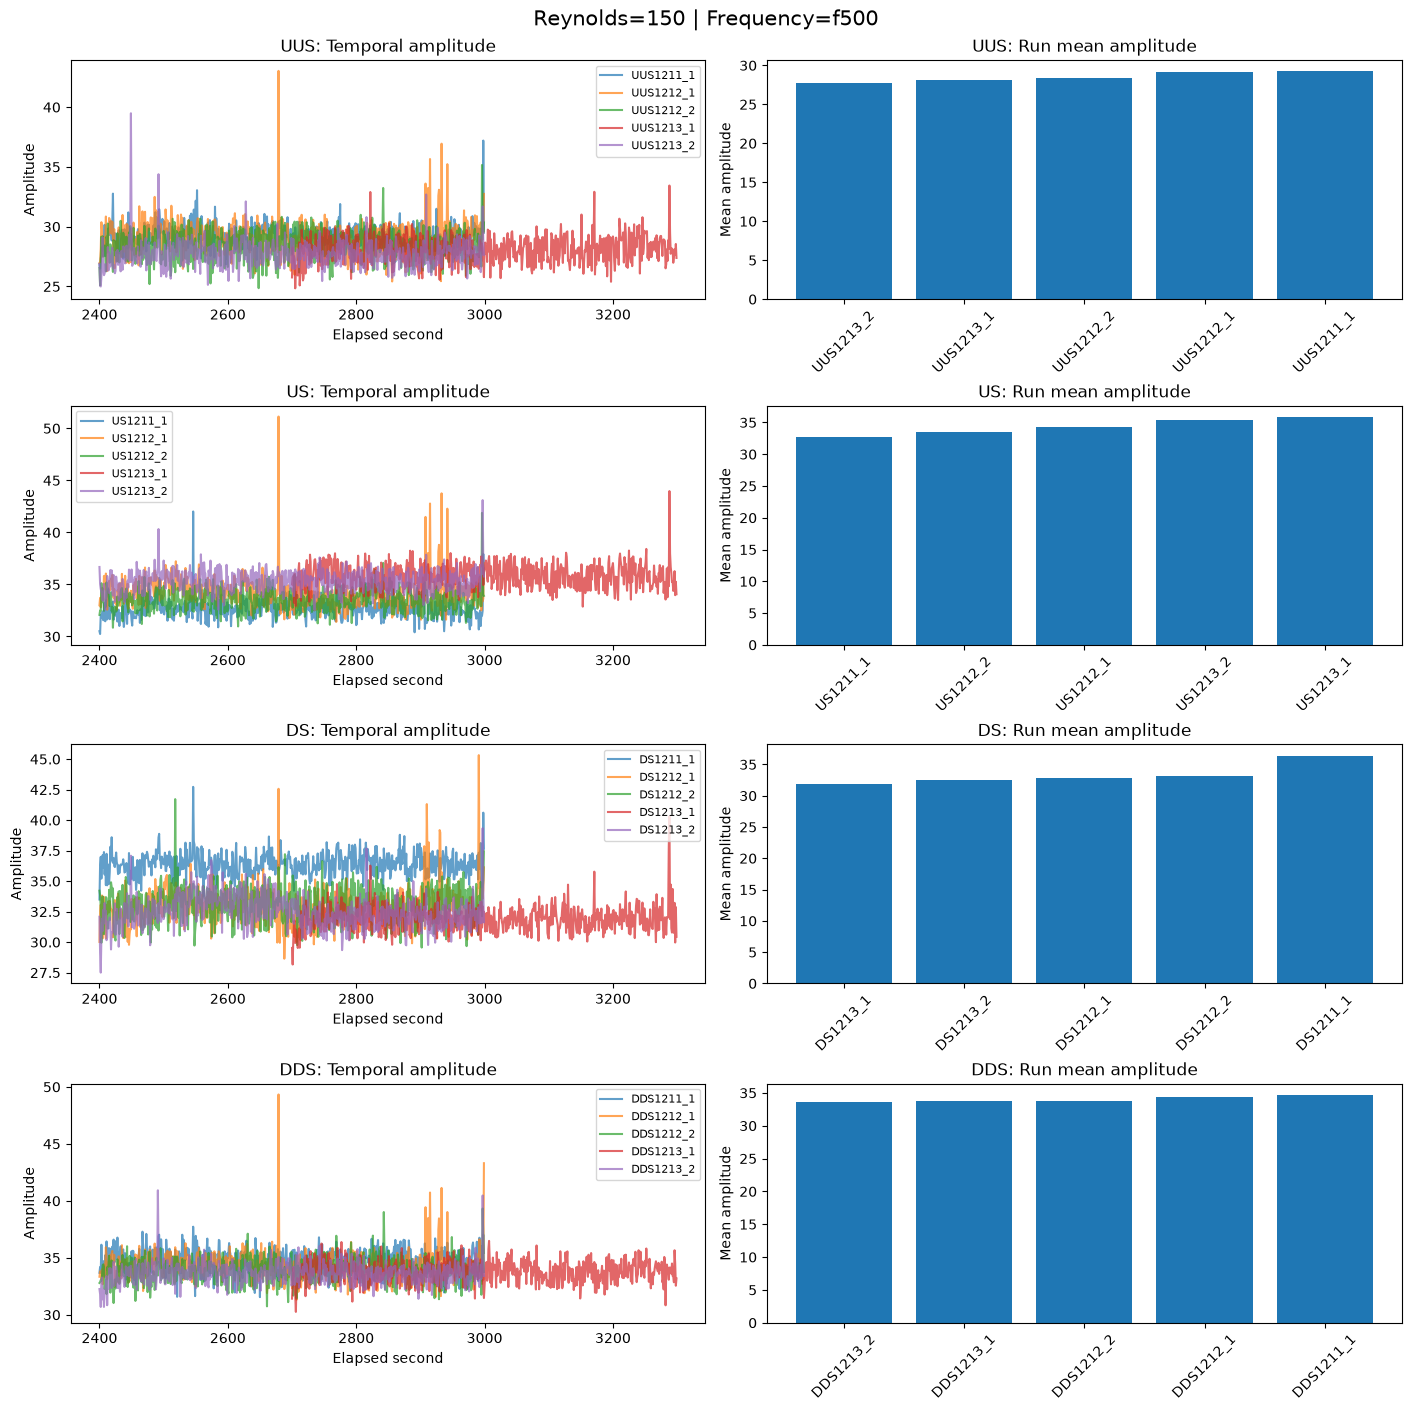

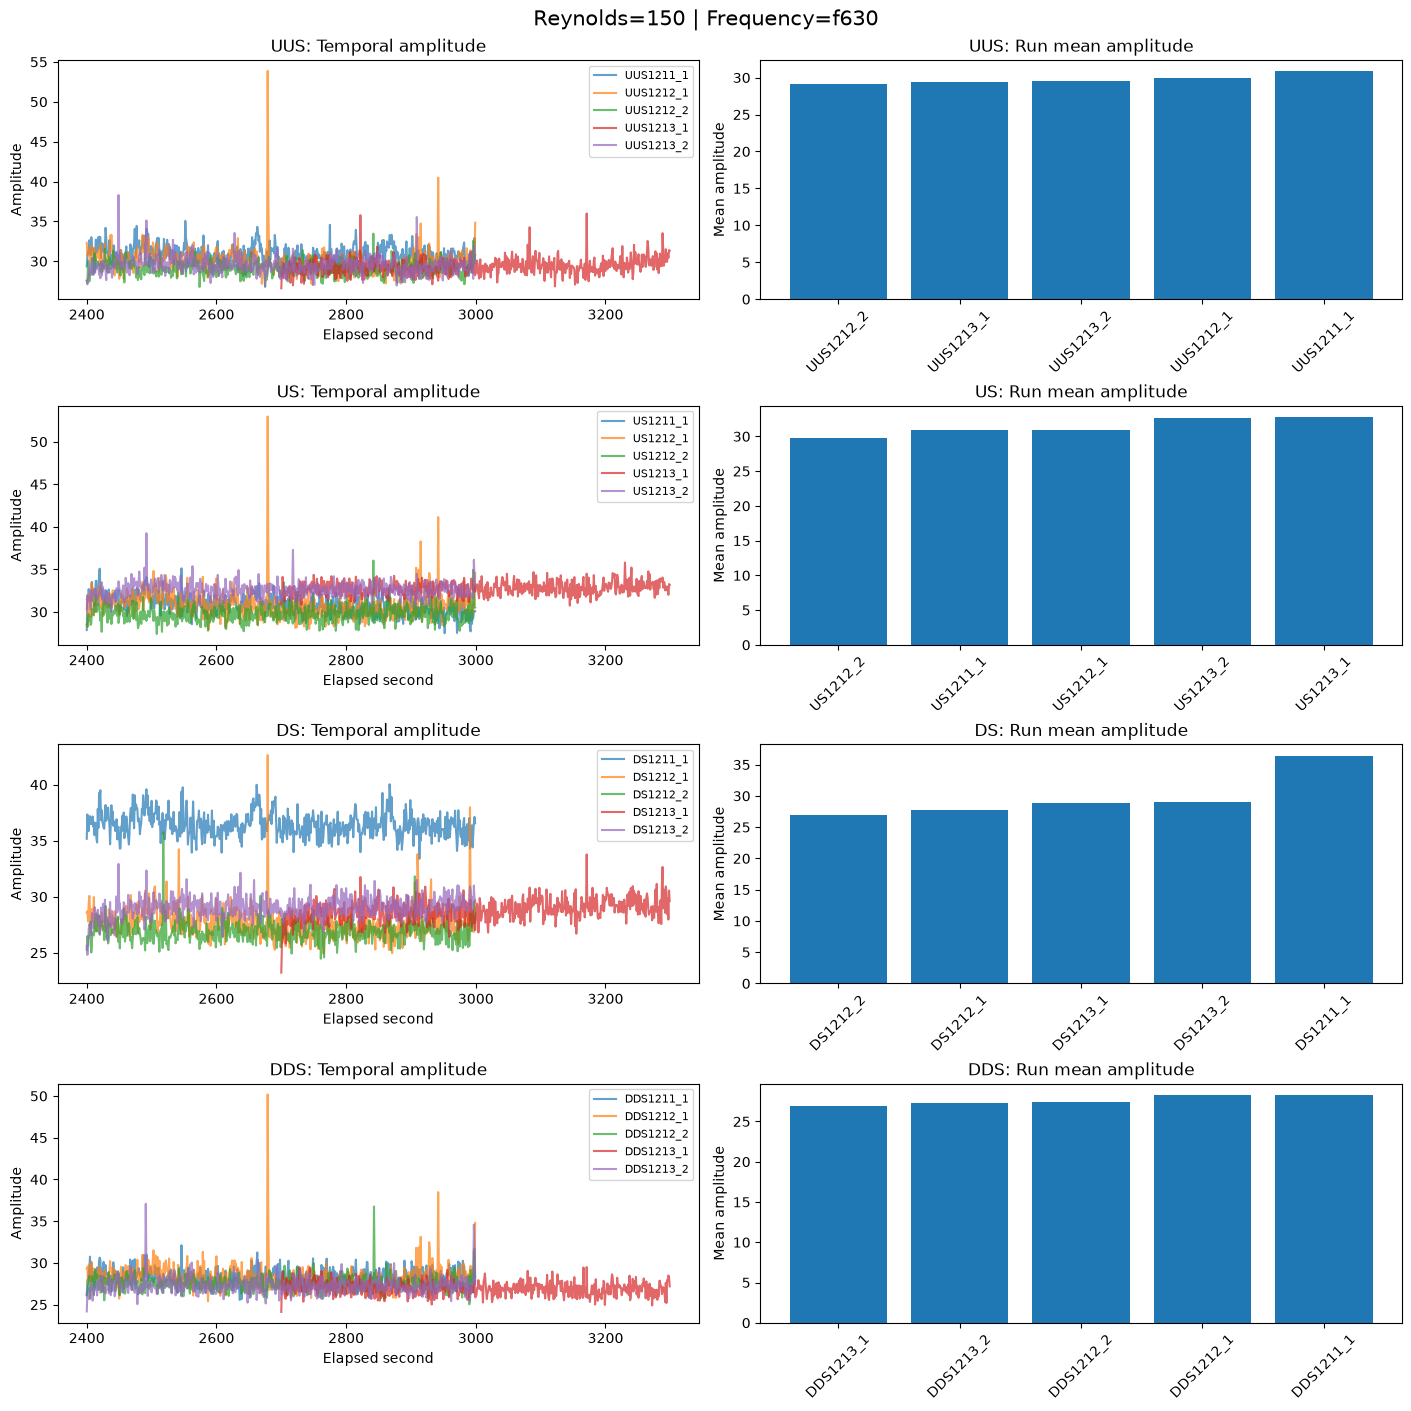

Saved all figures to: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/healthy_reproducibility_v2


In [61]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# USER INPUTS
# ============================================================
levels = [100.0, 150.0]
freq_min = 250
freq_max = 630

probes = ["UUS", "US", "DS", "DDS"]

OUT = Path(OUT)
OUT.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. FILTER FREQUENCIES AND REYNOLDS LEVELS
# ============================================================
def filter_ret_freq(df, levels, freq_min, freq_max):
    freq_numeric = pd.to_numeric(
        df["frequency"]
          .astype(str)
          .str.removeprefix("f")
          .str.replace("_", ".", regex=False),
        errors="coerce"
    )

    return df[
        df["Reynolds_level"].isin(levels) &
        freq_numeric.between(freq_min, freq_max)
    ].copy()


# Use the existing long dataframe containing time series
filtered = filter_ret_freq(
    long,
    levels=levels,
    freq_min=freq_min,
    freq_max=freq_max
)

# ============================================================
# 2. PLOT EVERY REYNOLDS × FREQUENCY COMBINATION
# ============================================================
combinations = (
    filtered[["Reynolds_level", "frequency"]]
    .drop_duplicates()
    .sort_values(["Reynolds_level", "frequency"])
)

print(f"Generating {len(combinations)} figures")

for level, freq in combinations.itertuples(index=False, name=None):

    fig, axes = plt.subplots(
        4, 2, figsize=(14, 14), layout="constrained"
    )

    for i, probe in enumerate(probes):

        sub = filtered[
            (filtered["probe"] == probe) &
            (filtered["Reynolds_level"] == level) &
            (filtered["frequency"] == freq)
        ].copy()

        ax_time, ax_mean = axes[i]

        if sub.empty:
            ax_time.text(
                0.5, 0.5, "No data",
                ha="center", va="center",
                transform=ax_time.transAxes
            )
            ax_mean.axis("off")
            continue

        # Left: temporal amplitude across experiments
        for file, g in sub.groupby("file_name"):
            g = g.sort_values("Date-Time")

            ax_time.plot(
                g["Date-Time"],
                g["amplitude"],
                alpha=0.7,
                label=file
            )

        ax_time.set_title(f"{probe}: Temporal amplitude")
        ax_time.set_xlabel("Elapsed second")
        ax_time.set_ylabel("Amplitude")
        ax_time.legend(fontsize=8)

        # Right: mean amplitude per experiment
        means = (
            sub.groupby("file_name")["amplitude"]
            .mean()
            .sort_values()
        )

        ax_mean.bar(means.index, means.values)
        ax_mean.set_title(f"{probe}: Run mean amplitude")
        ax_mean.set_ylabel("Mean amplitude")
        ax_mean.tick_params(axis="x", rotation=45)

    fig.suptitle(
        f"Reynolds={level:g} | Frequency={freq}",
        fontsize=15
    )

    filename = OUT / f"comparison_Re_{level:g}_{freq}.png"

    fig.savefig(filename, dpi=160)
    plt.show()
    plt.close(fig)

print(f"Saved all figures to: {OUT}")


In [64]:
filename = OUT / f"comparison_Re_Selected.csv"

filtered_tests.to_csv(filename,index=False)


## 7. Build a representative unique-key dataset **without synthetic mixed-frequency spectra**

**Strategy:** Within each `(probe, Reynolds_level)`, choose a **single representative source run** whose 27-frequency run-mean vector is closest to the multirun center. Distances are scaled by per-frequency robust between-run scale to avoid domination by high-amplitude channels. For each `(Date-Time, Reynolds_level, probe)`, take the complete observed 27-frequency row from that preferred run; if absent at a second, fall back to the next ranked run. This yields exactly one **observed** spectrum per key, never per-frequency mixing.

**Limitations:** fallback can create a discontinuity in a time sequence; the representative dataset is for **static EDA / benchmarking**, **not automatically suitable for LSTM training**. Preserve complete original runs for sequential training, and split train/test by run. The output records selected `file_name` and fallback rank. We do not claim it is the physical truth.

In [ ]:
# Rank complete runs by proximity to the run-mean center, per probe × Reynolds level.
# Use the common set of available frequencies for each run; missing channels are penalized.
rank_rows=[]
for (probe,level),g in eligible.groupby(['probe','Reynolds_level'],observed=True):
    mat=g.pivot_table(index='file_name',columns='frequency',values='run_mean').reindex(columns=freqs)
    center=mat.median(axis=0)
    scale=(mat-center).abs().median(axis=0)*1.4826
    # Fallback scaling when there is no between-run dispersion (or only one run)
    scale=scale.where(scale>1e-6,1.0)
    dist=((mat-center)/scale).pow(2).mean(axis=1,skipna=True).pow(.5)
    missing=mat.isna().sum(axis=1)
    scores=dist.fillna(np.inf)+missing*10
    for rank,(name,score) in enumerate(scores.sort_values().items(),start=1):
        rank_rows.append({'probe':probe,'Reynolds_level':level,'file_name':name,
                          'preference_rank':rank,'distance_score':score})
run_ranking=pd.DataFrame(rank_rows)
run_ranking.to_csv(OUT/'representative_run_ranking.csv',index=False)
display(run_ranking.groupby(['probe','Reynolds_level'],group_keys=False).head(2))

# Keep original observations; do not synthesize frequency values.
representative=(df.merge(run_ranking,on=['probe','Reynolds_level','file_name'],how='left')
                .sort_values(['probe','Reynolds_level','Date-Time','preference_rank','file_name'])
                .drop_duplicates(['probe','Reynolds_level','Date-Time'],keep='first').copy())
# A run with insufficient data for ranking should not be silently selected.
if representative['preference_rank'].isna().any():
    warnings.warn('Some selected observations have no ranked run (insufficient samples); inspect before use')
representative=representative.sort_values(['Date-Time','Reynolds_level','probe']).reset_index(drop=True)
assert not representative.duplicated(['Date-Time','Reynolds_level','probe']).any()
representative.to_csv(OUT/'healthy_representative_wide.csv',index=False)
rep_long=representative.melt(id_vars=['Date-Time','Reynolds_level','probe','file_name','preference_rank'],
                             value_vars=freqs,var_name='frequency',value_name='amplitude')
assert not rep_long.duplicated(['Date-Time','Reynolds_level','probe','frequency']).any()
rep_long.to_csv(OUT/'healthy_representative_long.csv',index=False)
print('Wide rows:',len(representative),'Long rows:',len(rep_long))
print('Fallback fraction:',round((representative['preference_rank']>1).mean(),4))
print('Unique key violations:',int(representative.duplicated(['Date-Time','Reynolds_level','probe']).sum()))
display(representative.groupby(['probe','Reynolds_level']).agg(
    n_rows=('Date-Time','size'),n_source_files=('file_name','nunique'),
    fallback_rows=('preference_rank',lambda x:(x>1).sum())).reset_index())

## 8. Continuity audit and final decision checklist

A one-row-per-key dataset does not ensure four probes are from the same physical run or that adjacent seconds are continuous. Audit switching and spatial coherence before using any representative rows for a multichannel model. **Recommended next experiment:** train/evaluate Stage 1 on complete pre-leak runs with leave-one-run-out validation; compare errors by probe × Reynolds × frequency and relate false positives to between-run shifts. The representative dataset is an EDA artifact, not a substitute for experimental replication.

In [ ]:
# Count source-run changes across successive retained seconds within each probe/level.
audit=[]
for (probe,level),g in representative.groupby(['probe','Reynolds_level']):
    g=g.sort_values('Date-Time')
    changed=g['file_name'].ne(g['file_name'].shift())
    audit.append({'probe':probe,'Reynolds_level':level,'n_rows':len(g),
                  'source_switches':max(0,int(changed.sum())-1),
                  'n_source_runs':g['file_name'].nunique()})
continuity=pd.DataFrame(audit)
continuity.to_csv(OUT/'representative_continuity_audit.csv',index=False)
display(continuity)
print('All files saved under:',OUT)